# Do temperature and seeds change an LLM's algorithm? — runnable CPU demo (task T2)

This notebook walks through the artifact's `method.py` pipeline. The pipeline screened **Qwen3-8B** (vLLM 0.11.0,
one RTX 5090) on two path-search coding tasks, 5,220 generations in total. It asks whether the usual "creativity
knobs" change **which algorithm** the model writes (a new **idea**) or only **how the same algorithm is worded** (a
new **phrasing**). The knobs are sampling temperature, random context seeds, creativity instructions and
gen-then-select.

**Task T2, shown here.** *"Write `solve(n, edges, s, t)` that returns the shortest-path length in a directed graph
with integer weights 0..100."* The model's default answer is Dijkstra. Every generated program is labelled **by
executing it**:

- hidden tests decide correctness;
- a runtime-signature tracer (heap, queue and edge-list instrumentation on crafted graphs) and AST rules decide the
  algorithm;
- a blind LLM judge settles the few disagreements.

**What this notebook re-runs** (CPU only, a few minutes): the `label` → `analyze` → `output` stages of `method.py`.
They run on a **label-blind subset of 100 stored T2 generations** and on the stored **layer-22 read-position hidden
states** (output of the `hooks` stage), which are used for the activation-geometry analysis. The GPU stages
(`generate`: vLLM sampling of the 8B model; `hooks`: Hugging Face forward passes) and the OpenRouter judge/`gate` are
**not** re-run. Their outputs are loaded from `mini_demo_data.json`.

| `method.py` stage | original module(s) | in this notebook |
|---|---|---|
| `setup` | `tasks/`, `harness/`, `prompts/` | hidden tests, limits and references loaded; harness and references re-checked |
| `generate` | `gen/arms.py` (vLLM, GPU) | **loaded**: 100 stored generations (prompt + answer) |
| `label` | `labeller/label.py`, `tracer.py`, `ast_rules.py`, `harness/run_tests.py` | **re-run**: tests + runtime tracer + AST rules; judge verdicts loaded |
| `gate` | `labeller/gold.py` (OpenRouter judges) | **loaded**: stored gate metrics |
| `hooks` | `hooks/states.py` (HF, GPU) | **loaded**: R states at layer l\*=22 |
| `analyze` | `analysis/*.py` | **re-run**: 8a, 8b, 8c, 8g/8h, 8d, plus the MDS geometry figure |
| `output` | `method.py: build_method_out` | **re-run** on the demo subset |

**Full-run findings**, which the demo re-derives on its subset:

1. Temperature does not change the algorithm: Dijkstra is 797/800 with thinking off.
2. Phrasings grow with T while ideas stay at about 1; on T2 the rise is small.
3. Random seeds (`seed=d32qxk4nt43`, `seed=(horse chair roof love)`) shift nothing.
4. A **semantic seed** (a story that implies Bellman-Ford without naming it) moves Dijkstra by **−67 pp**.
   "Fully novel" instructions move it by −15 pp.
5. **Gen-then-select** (list 10 approaches, an external RNG picks one) reaches about 3 distinct ideas, but the pass
   rate drops to 75%.
6. Inside the model, the semantic seed moves the read-position state **3.7×** further than paraphrase noise in the
   "mode subspace" spanned by forced-algorithm prompts. Random seeds stay within paraphrase noise.

**Caveat:** the labeller gate failed its strict criteria, so the artifact reports these results as *descriptive*.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# The CPU stages re-run here (label, analyze, output) only need numpy, scipy, scikit-learn, matplotlib and pandas,
# all pre-installed on Colab. The GPU stages (vllm 0.11.0, torch 2.8, transformers 4.57) and the OpenRouter judge
# (openai) are not re-run, so nothing outside Colab's stack is needed.
# Locally (no google.colab) install the same packages at Colab's exact versions so the environment matches Colab.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

import os
# notebook: cap BLAS threads before numpy is imported. On many-core hosts with a CPU quota, OpenBLAS's default (one
# thread per visible core) makes the 260x4096 SVD inside the 8d subspace test ~100x slower (24 s instead of 0.2 s).
for _v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "4")

# --- method.py import block (as in the original) ---
import argparse
import hashlib
import json
import subprocess
import sys
import time
from pathlib import Path

# --- imports of the modules that method.py runs (common, harness, labeller, analysis) ---
import ast
import base64
import builtins
import math
import random
import re
import tempfile
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from typing import Any, Callable, Iterable, Sequence

import numpy as np

# --- notebook additions: tables and figures ---
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-1/experiment-6/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
md = data["metadata"]
print(md["method_name"])
print("top-level keys :", list(data))
print("demo subset    :", md["demo_subset"]["n_examples"], "generations of task", md["demo_subset"]["task"],
      "| rule:", md["demo_subset"]["rule"])
print("model / engine :", md["setup"]["model"], "| vLLM", md["setup"]["vllm_version"], "|", md["setup"]["gpu"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Temperature and seeds: new ideas or rewording? (screen)
top-level keys : ['metadata', 'hidden_tests', 'references', 'r_states', 'datasets']
demo subset    : 100 generations of task T2 | rule: per cell: sort by (sample_id, paraphrase_id), take the first n (label-blind)
model / engine : Qwen/Qwen3-8B | vLLM 0.11.0 | NVIDIA GeForce RTX 5090


## Configuration

Every knob below exists in the original pipeline; the comment gives the full-run value. The demo data holds 8–12
generations per cell (the full run had 100). `MAX_PER_CELL` keeps fewer of them.

`DA_K` is the *K* of DA@K, the expected number of distinct ideas or phrasings in *K* draws (Lee et al.). The full
run used K=25. The demo cells hold about 10 correct programs, so K must be at most the cell size. The output keys
keep their original names (`DA_idea_25`, `DA_phr_25`) but are computed with `K = DA_K`.

In [5]:
# ---------------- demo configuration (original full-run values in the comments) ----------------
MAX_PER_CELL = 12           # generations kept per (arm, condition, T) cell; the file holds 8-12 (full run: 100)
LABEL_WORKERS = 2          # labelling workers (threads driving the test/tracer subprocesses); original: 12 processes
N_BOOT = 2000                # paraphrase-cluster bootstrap draws in 8a / 8c (original 2000)
N_PERM = 5000                # cluster permutations in 8c (original 5000)
N_BOOT_PHRASING = 1000       # program-bootstrap draws for the 8b slopes in T (original 1000)
DA_K = 5                   # K of DA@K (original 25); must not exceed the per-cell number of correct programs
N_BOOT_SUBSPACE = 2000       # 8d bootstrap draws of the displacement ratio (original 2000)
N_PERM_SUBSPACE = 10000       # 8d mean-shift permutations (original 10000)
N_NULL_SUBSPACE = 100        # 8d random subspaces per null distribution (original 100)
SEED = 11                  # RNG seed of the subspace analysis (analysis/run_all.py: np.random.default_rng(11))

## `method.py`: the orchestrator

`method.py <stage>` runs each stage as its own process and logs it. A GPU stage never shares the device with
another stage.

- `setup`: hidden tests, time limits, reference gate and prompt scaffold.
- `generate`: vLLM arms → `results/raw/<arm>.jsonl`.
- `label`: tests + tracer + AST + judge → `results/samples.jsonl`.
- `gate`: gold set and labeller gate.
- `hooks`: HF activation block, R states and probes.
- `analyze`: sections 8a–8i, verdicts and figures.
- `output`: `method_out.json`.

The arms are:

- **A0**: no-cue baseline, pure sampling at T=1.0.
- **A1**: temperature grid T ∈ {0.3, 0.7, 1.0, 1.3} × {top-k=10, top-p=0.95}, thinking off.
- **A2**: seeds (entropy, word, semantic).
- **A3**: creativity instructions.
- **A4**: gen-then-select.
- **A5**: forced implementations.
- **A6**: the temperature grid with thinking on.

Every cue is compared with A0 at matched decoding. The cell below is `method.py`'s own record of where the run
departed from the plan.

In [6]:
# ---- method.py: documented deviations from the plan (verbatim) ----
DEVIATIONS = [
    dict(what="GPU was an RTX 5090 (32 GB) instead of a 20 GB card: max_num_seqs=128 (plan 16) and thinking-on "
              "cells have N=100 (10 paraphrases x 10) instead of N=50; all four thinking-on cells per task ran",
         why="more KV-cache capacity (92k tokens) and ~4k tok/s throughput", effect="more power for thinking-on "
         "cells; no planned arm was dropped"),
    dict(what="vLLM 0.11.0 started with enforce_eager=True (no CUDA graphs / torch.compile)",
         why="the container has no C compiler, so Triton/Inductor compilation cannot run", effect="speed only"),
    dict(what="HF_HOME was not set to ./hf_cache; Qwen/Qwen3-8B was read from the run's shared HF cache",
         why="the run's shared cache variables must not be overridden", effect="none on outputs"),
    dict(what="per-request seed = stable hash of (task, condition, paraphrase, sample, arm, T, sampler, thinking) "
              "instead of (task, condition, paraphrase, sample)",
         why="so that different decoding cells are independent draws rather than common-random-number pairs",
         effect="cells are independent samples, matching the per-cell bootstrap"),
    dict(what="forced:X uses 20 frames = 10 neutral preambles x 2 templates; described:X uses 2 name-free "
              "descriptions x 5 preambles per mode", why="the plan fixes counts but not the frame construction",
         effect="none"),
    dict(what="A4 stage 1 has no paraphrase preambles (paraphrase_id=-1); its bootstrap treats each sample as a cluster",
         why="the plan's stage-1 prompt has no preamble", effect="none"),
    dict(what="tracer uses sys.settrace for both call/return (recursion depth, call expansions) and line events",
         why="one trace function covers both; sys.setprofile would duplicate the call bookkeeping", effect="none"),
    dict(what="IDDFS reference written in the common recursive form (best-depth map per iteration) plus an "
              "iterative-stack variant; serpentine T1 test fixed (its goal cell was a wall)",
         why="first version did not match model-written IDDFS and the test case violated the spec",
         effect="labeller validated on both IDDFS forms; hidden tests regenerated before any scoring"),
    dict(what="tracer crafted graphs W1/W2 made strongly connected (Hamiltonian cycle) with a FIFO re-relaxation "
              "gadget next to s; Floyd-Warshall rule also accepts growth >= 2.2 with >= n^3/2 line events",
         why="on the planned generator SPFA never re-popped a node and an INF-skipping Floyd-Warshall grew as n^1.4",
         effect="100% runtime labels on references (pre-gate change, logged)"),
    dict(what="two rounds of labeller signature revision after the first gate (see labeller_gate.revisions)",
         why="gate failures traced to stale-pop handling, Bellman-Ford over adjacency lists, and sequential double "
             "Dijkstra mislabelled bidirectional", effect="samples needing the judge fell from 247 to 116 (of 5,220)"),
    dict(what="labeller gate failed on both tasks by the strict criterion and both tasks carry the flag "
              "'labeller_gate_failed'; their results are descriptive",
         why="kappa(runtime, AST) on the gold set is low by construction (the gold set oversamples disagreements; "
             "population kappa is 0.88 / 0.85); T2 gold agreement 70% because the gold judges call broken "
             "attempts 'other' while the pipeline labels the attempted structure",
         effect="verdicts are reported mechanically but marked descriptive; agreement on correct gold programs is "
                "92% on both tasks"),
    dict(what="probe nulls: 200 shuffled-label permutations for transfer accuracy in layers 8-28 (50 elsewhere); "
              "leave-one-frame-out null uses 20 permutations",
         why="time budget", effect="l* selection uses the planned 200-permutation transfer null"),
    dict(what="S_nat skipped on both tasks; variance split uses S_gen (primary) and S_R",
         why="natural samples have < 2 modes with >= 5 samples (fallback 5)", effect="as planned"),
    dict(what="variance-split data-matched null frames are drawn inside the top-50 PCs of the pooled generated-"
              "position states of the task (not the R states)",
         why="the null should match the space whose variance is being split", effect="excess-share values"),
    dict(what="max_model_len=4096 (shared protocol 2048) and max_tokens=1536 for instr_enumerate",
         why="planned deviations", effect="none on thinking-off outputs"),
]

for i, dv in enumerate(DEVIATIONS, 1):
    print(f"{i:2d}. {dv['what'][:160]}{' ...' if len(dv['what']) > 160 else ''}")

 1. GPU was an RTX 5090 (32 GB) instead of a 20 GB card: max_num_seqs=128 (plan 16) and thinking-on cells have N=100 (10 paraphrases x 10) instead of N=50; all four ...
 2. vLLM 0.11.0 started with enforce_eager=True (no CUDA graphs / torch.compile)
 3. HF_HOME was not set to ./hf_cache; Qwen/Qwen3-8B was read from the run's shared HF cache
 4. per-request seed = stable hash of (task, condition, paraphrase, sample, arm, T, sampler, thinking) instead of (task, condition, paraphrase, sample)
 5. forced:X uses 20 frames = 10 neutral preambles x 2 templates; described:X uses 2 name-free descriptions x 5 preambles per mode
 6. A4 stage 1 has no paraphrase preambles (paraphrase_id=-1); its bootstrap treats each sample as a cluster
 7. tracer uses sys.settrace for both call/return (recursion depth, call expansions) and line events
 8. IDDFS reference written in the common recursive form (best-depth map per iteration) plus an iterative-stack variant; serpentine T1 test fixed (its goal cell was

## `common.py`: task text and algorithm catalogue

The catalogue fixes the set of *ideas* the labeller can assign for T2: Dijkstra, Bellman-Ford/SPFA, bidirectional
Dijkstra, Floyd-Warshall and Dial's bucket queue. Anything else is labelled `other`. `PRIMARY_MODE` is the model's
default (modal) idea. The cell also creates a small scratch folder `demo_work/`. It replaces the artifact's
`tests/` and `results/` paths and holds the two subprocess drivers.

In [7]:
# ---- common.py (subset used by the CPU stages; paths, logging and GPU helpers omitted) ----
TASKS = ("T1", "T2")
TASK_TEXT = {
    "T1": ("Write a Python function solve(grid, start, goal). grid is a list of strings of equal length; . is an "
           "open cell and # is a wall. start and goal are (row, col) tuples of open cells. Moves go up, down, left "
           "or right. Return any valid path from start to goal as a list of (row, col) tuples that begins with "
           "start, ends with goal and visits only open cells, or [] if goal is unreachable. Grids have at most 30 "
           "rows and 30 columns. Return only one ```python code block containing solve and any helpers."),
    "T2": ("Write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); "
           "edges is a list of (u, v, w) tuples with integer weight 0 <= w <= 100; cycles, self-loops and parallel "
           "edges may occur. Return the length of the shortest path from s to t, 0 if s == t, or -1 if t is "
           "unreachable. Return only one ```python code block containing solve and any helpers."),
}
OUTPUT_FORMAT_SENTENCE = "Return only one ```python code block containing solve and any helpers."
TASK_TEXT_NO_FORMAT = {k: v.replace(" " + OUTPUT_FORMAT_SENTENCE, "") for k, v in TASK_TEXT.items()}

# Catalogue: mode -> (display name used in forced prompts, one-line definition used by the judge)
CATALOGUE: dict[str, dict[str, tuple[str, str]]] = {
    "T1": {
        "bfs": ("breadth-first search (BFS)",
                "breadth-first search: a FIFO queue expands cells in order of distance from start"),
        "dfs": ("depth-first search (DFS)",
                "depth-first search: a LIFO stack or recursion follows one branch as deep as possible before "
                "backtracking (recursive and iterative versions are the same algorithm)"),
        "bidirectional_bfs": ("bidirectional breadth-first search",
                              "bidirectional BFS: two FIFO frontiers grow from start and from goal and stop "
                              "when they meet"),
        "iddfs": ("iterative deepening depth-first search (IDDFS)",
                  "iterative deepening DFS: repeated depth-limited DFS with an increasing depth limit"),
        "astar_greedy": ("A* search with a Manhattan-distance heuristic",
                         "heuristic best-first search: a priority queue ordered by a goal-distance heuristic "
                         "h (greedy best-first) or by g+h (A*)"),
        "dijkstra_unit": ("Dijkstra's algorithm with a priority queue",
                          "Dijkstra / uniform-cost search: a priority queue ordered by path cost g only, "
                          "no heuristic"),
    },
    "T2": {
        "dijkstra": ("Dijkstra's algorithm",
                     "Dijkstra: repeatedly settle the unsettled node with the smallest tentative distance "
                     "(binary heap or linear scan), relaxing its outgoing edges"),
        "bellman_ford_spfa": ("the Bellman-Ford algorithm",
                              "Bellman-Ford / SPFA: relax all edges in rounds until nothing changes, or a FIFO "
                              "queue of nodes whose distance changed (nodes may be processed many times)"),
        "bidirectional_dijkstra": ("bidirectional Dijkstra's algorithm",
                                   "bidirectional Dijkstra: one Dijkstra search forward from s and one backward "
                                   "from t over reversed edges, stopping when the frontiers meet"),
        "floyd_warshall": ("the Floyd-Warshall algorithm",
                           "Floyd-Warshall: all-pairs dynamic programming over an n x n distance matrix with "
                           "three nested loops over k, i, j"),
        "dial": ("Dial's algorithm (a bucket-based priority queue)",
                 "Dial's algorithm: Dijkstra with an array of buckets indexed by integer distance instead of "
                 "a heap"),
    },
}
MODES = {t: list(CATALOGUE[t]) for t in TASKS}
PRIMARY_MODE = {"T1": "bfs", "T2": "dijkstra"}
NON_CLASSIFIED = {"other", "unparseable", "unresolved", None}

# Lexicon of catalogue names and aliases (used to check that seeds and descriptions never name an algorithm,
# and to find plan statements in thinking traces).
ALIAS_LEXICON = {
    "bfs": [r"\bbfs\b", r"breadth[- ]first", r"breadth first"],
    "dfs": [r"\bdfs\b", r"depth[- ]first", r"backtrack"],
    "bidirectional_bfs": [r"bi-?directional", r"two[- ]way search", r"meet in the middle", r"meet-in-the-middle"],
    "iddfs": [r"\biddfs\b", r"iterative[- ]deepening", r"depth[- ]limited"],
    "astar_greedy": [r"\ba\*", r"\ba-star\b", r"\bastar\b", r"best[- ]first", r"greedy best"],
    "dijkstra_unit": [r"dijkstra", r"uniform[- ]cost"],
    "dijkstra": [r"dijkstra"],
    "bellman_ford_spfa": [r"bellman", r"\bford\b", r"\bspfa\b", r"shortest path faster"],
    "bidirectional_dijkstra": [r"bi-?directional dijkstra"],
    "floyd_warshall": [r"floyd", r"warshall", r"all[- ]pairs"],
    "dial": [r"\bdial'?s?\b(?! a)", r"bucket[- ]?queue", r"radix heap"],
}


def stable_seed(*parts: Any) -> int:
    """Deterministic 31-bit seed from arbitrary parts (stable across processes, unlike hash())."""
    h = hashlib.sha256("|".join(map(str, parts)).encode()).hexdigest()
    return int(h[:8], 16) & 0x7FFFFFFF


def sha256_text(text: str) -> str:
    return hashlib.sha256(text.encode()).hexdigest()


def write_json(path: Path, obj: Any, indent: int | None = 2) -> None:
    tmp = Path(str(path) + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, default=_json_default))
    tmp.replace(path)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not math.isfinite(float(o)) else float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serializable: {type(o)}")


# notebook: a scratch folder stands in for the artifact's tests/ and results/ folders and holds the two drivers
WORK = Path("demo_work")
for _d in (WORK / "harness", WORK / "labeller", WORK / "tests"):
    _d.mkdir(parents=True, exist_ok=True)
TESTS_DIR = (WORK / "tests").resolve()

assert TASK_TEXT == md["setup"]["task_text"], "task text differs from the one used in the run"
TASK = md["demo_subset"]["task"]
print(f"{TASK}: {TASK_TEXT[TASK]}\n")
for m, (name, definition) in CATALOGUE[TASK].items():
    print(f"  {m:24s} {definition}")

T2: Write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); edges is a list of (u, v, w) tuples with integer weight 0 <= w <= 100; cycles, self-loops and parallel edges may occur. Return the length of the shortest path from s to t, 0 if s == t, or -1 if t is unreachable. Return only one ```python code block containing solve and any helpers.

  dijkstra                 Dijkstra: repeatedly settle the unsettled node with the smallest tentative distance (binary heap or linear scan), relaxing its outgoing edges
  bellman_ford_spfa        Bellman-Ford / SPFA: relax all edges in rounds until nothing changes, or a FIFO queue of nodes whose distance changed (nodes may be processed many times)
  bidirectional_dijkstra   bidirectional Dijkstra: one Dijkstra search forward from s and one backward from t over reversed edges, stopping when the frontiers meet
  floyd_warshall           Floyd-Warshall: all-pairs dynamic programming over an n x n distance mat

## Stage `generate` (loaded, not re-run): prompts and stored generations

Each prompt is *preamble [+ cue]* followed by the task text. The 10 paraphrase preambles act as clusters for the
bootstrap and permutation tests. The cue is empty for the baseline. Otherwise it is one of:

- an entropy seed;
- a word seed;
- a semantic seed: a story implying Bellman-Ford-style rounds of relaxation, which never names an algorithm;
- a creativity instruction.

For gen-then-select, the model first lists 10 approaches. An external RNG picks one, and the stage-2 prompt asks
for exactly that approach. The cell checks that every stored prompt rebuilds exactly from the `prompts/build.py`
constants.

In [8]:
# ---- prompts/build.py (constants of the paired prompt scaffold, verbatim) ----
PREAMBLES = [
    "Here is a programming task.",
    "Please solve the task below.",
    "Below is a coding problem.",
    "Consider the following task.",
    "The task is described below.",
    "Here is a problem to solve in Python.",
    "Please complete the following assignment.",
    "Read the task below and solve it.",
    "This is a coding exercise.",
    "The following is a programming problem.",
]

SEED_ENTROPY = "seed=d32qxk4nt43"
SEED_WORD = "seed=(horse chair roof love)"
SEMANTIC_IMPLIED = {"T1": "bidirectional_bfs", "T2": "bellman_ford_spfa"}

INSTRUCTIONS = {
    "instr_creative": [
        "Be creative.", "Be inventive.", "Show some creativity.", "Take a creative approach.",
        "Feel free to be creative.", "Approach this creatively.", "Use your creativity.", "Be imaginative.",
        "Get creative with it.", "Let your creativity show.",
    ],
    "instr_new_algo": [
        "Make a new algorithm.", "Design a new algorithm.", "Invent a new algorithm for this.",
        "Come up with a new algorithm.", "Create a new algorithm.", "Devise a new algorithm.",
        "Build a new algorithm for it.", "Write a new algorithm.", "Develop a new algorithm.",
        "Use a new algorithm of your own.",
    ],
    "instr_fully_novel": [
        "Make a fully novel algorithm never seen before.",
        "Invent a completely novel algorithm that has never been seen before.",
        "Design an entirely new algorithm nobody has seen before.",
        "Create a fully original algorithm that does not exist yet.",
        "Come up with a totally novel algorithm never used before.",
        "Devise a brand-new algorithm unlike anything seen before.",
        "Build a fully novel algorithm that no one has ever written.",
        "Write a completely original algorithm never seen before.",
        "Develop an algorithm so novel that it has never appeared before.",
        "Make an algorithm that is fully novel and never seen before.",
    ],
    "instr_enumerate": [
        "First list 10 different approaches to this task, one line each, then implement one of them.",
        "Begin by listing 10 different approaches to this task, one per line, and then implement one of them.",
        "Start with a list of 10 different ways to solve this task, one line each; then implement one.",
        "List 10 different approaches to this task first, one line each, and then implement one of them.",
        "Before coding, write down 10 different approaches to this task, one per line, then implement one.",
        "First enumerate 10 different approaches to this task, one line each, then pick one and implement it.",
        "Name 10 different approaches to this task first, one line each, then implement one of them.",
        "Give a list of 10 different approaches to this task, one per line, then implement one of them.",
        "First write 10 different approaches to this task as a one-line-each list, then implement one.",
        "Start by listing 10 distinct approaches to this task, one line each, then implement one of them.",
    ],
}


def user_message(seg: str, task: str, task_text: str | None = None) -> str:
    return seg + "\n\n" + (task_text if task_text is not None else TASK_TEXT[task])


# notebook: check that every stored prompt is exactly preamble [+ cue] + task text, and show one cue per condition
examples = data["datasets"][0]["examples"]
shown = set()
for e in examples:
    p, cond = e["metadata_paraphrase_id"], e["metadata_condition"]
    seg = e["input"].split("\n\n")[0]
    if cond == "gen_then_select":                       # stage-2 prompt: "Implement the following approach: ..."
        cue = seg
    else:
        assert seg.startswith(PREAMBLES[p]), e["metadata_key"]
        cue = seg[len(PREAMBLES[p]):].strip()
        expected = {"baseline": "", "seed_entropy": SEED_ENTROPY, "seed_word": SEED_WORD}.get(cond, cue)
        if cond in INSTRUCTIONS:
            expected = INSTRUCTIONS[cond][p]
        assert cue == expected, e["metadata_key"]
    assert user_message(seg, TASK) == e["input"], e["metadata_key"]
    if cond not in shown:
        shown.add(cond)
        print(f"[{cond}]  preamble: {PREAMBLES[p] if p >= 0 else '(none)'}\n    cue: {cue or '(none)'}\n")
print(f"all {len(examples)} stored prompts rebuild exactly from the scaffold")

[baseline]  preamble: Here is a programming task.
    cue: (none)

[seed_entropy]  preamble: Here is a programming task.
    cue: seed=d32qxk4nt43

[seed_word]  preamble: Here is a programming task.
    cue: seed=(horse chair roof love)

[seed_semantic]  preamble: Here is a programming task.
    cue: News spreads through a kingdom in rounds. In each round, every road carries a message from its source town to its destination town announcing how long the trip took so far plus the road's own travel time. Each town keeps only the shortest total it has ever heard. Once a whole round passes in which no town hears anything better, every town knows its true travel time.

[instr_fully_novel]  preamble: Here is a programming task.
    cue: Make a fully novel algorithm never seen before.

[gen_then_select]  preamble: (none)
    cue: Implement the following approach: Floyd-Warshall Algorithm - Compute the shortest paths between all pairs of nodes, then return the path from s to t.

all 100 stored 

In [9]:
# notebook: rebuild the generation rows (schema of results/raw/<arm>.jsonl) from the stored examples, keeping at
# most MAX_PER_CELL generations per cell in the stored (label-blind) order
per_cell = Counter()
rows = []
for e in examples:
    cell = (e["metadata_arm"], e["metadata_condition"], e["metadata_sampler"], e["metadata_temperature"])
    if per_cell[cell] >= MAX_PER_CELL:
        continue
    per_cell[cell] += 1
    r = dict(key=e["metadata_key"], task=TASK, condition=e["metadata_condition"], arm=e["metadata_arm"],
             paraphrase_id=e["metadata_paraphrase_id"], sample_id=e["metadata_sample_id"], model=e["metadata_model"],
             decoding=dict(T=e["metadata_temperature"], sampler=e["metadata_sampler"], top_k=e["metadata_top_k"],
                           top_p=e["metadata_top_p"], thinking=e["metadata_thinking"],
                           max_tokens=e["metadata_max_tokens"], seed=e["metadata_seed"]),
             n_output_tokens=e["metadata_n_output_tokens"], finish_reason=e["metadata_finish_reason"],
             truncated_thinking=e["metadata_truncated_thinking"], two_pass=e["metadata_two_pass"],
             n_thinking_tokens=e["metadata_n_thinking_tokens"], user_message=e["input"], answer_text=e["output"])
    if "metadata_gts_item" in e:
        r.update(gts_item=e["metadata_gts_item"], gts_k=e["metadata_gts_k"], gts_n_items=e["metadata_gts_n_items"])
    rows.append(r)
print(f"{len(rows)} generations in {len(per_cell)} cells")
display(pd.DataFrame([dict(arm=k[0], condition=k[1], sampler=k[2], T=k[3], n=v) for k, v in per_cell.items()]))
print("example generation:", rows[0]["key"])
print(rows[0]["answer_text"][:900])

100 generations in 10 cells


,arm,condition,sampler,T,n
0,A0,baseline,pure,1.0,10
1,A1,baseline,topk10,0.3,10
2,A1,baseline,topk10,0.7,10
3,A1,baseline,topk10,1.0,10
4,A1,baseline,topk10,1.3,10
5,A2,seed_entropy,pure,1.0,8
6,A2,seed_word,pure,1.0,8
7,A2,seed_semantic,pure,1.0,10
8,A3,instr_fully_novel,pure,1.0,12
9,A4s2,gen_then_select,pure,1.0,12


example generation: A0|T2|baseline|p0|s0|T1.0|pure|think0
```python
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    
    # Build adjacency list
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    
    # Dijkstra's algorithm
    dist = [float('inf')] * n
    dist[s] = 0
    heap = [(0, s)]
    
    while heap:
        current_dist, u = heapq.heappop(heap)
        if u == t:
            return current_dist
        if current_dist > dist[u]:
            continue
        for v, weight in adj[u]:
            if dist[v] > dist[u] + weight:
                dist[v] = dist[u] + weight
                heapq.heappush(heap, (dist[v], v))
    
    return -1
```


## Stage `label` (1/5): code extraction — `labeller/label.py`

The pipeline takes the last ```` ```python ```` block that defines `solve`. If there is none, it falls back to the
first Python block, then to an untagged block, then to the whole text.

In [10]:
# ---- labeller/label.py: code extraction (verbatim) ----
FENCE = re.compile(r"```[ \t]*([A-Za-z0-9_+-]*)[^\n]*\n(.*?)(?:```|\Z)", re.S)
SOLVE_DEF = re.compile(r"^\s*def\s+solve\s*\(", re.M)


def _parses(code: str) -> bool:
    try:
        ast.parse(code)
        return True
    except (SyntaxError, ValueError):
        return False


def extract_code(text: str) -> tuple[str | None, str]:
    """Last ```python block that defines solve; else the first ```python block; else the whole text if it parses."""
    if "</think>" in text:
        text = text.split("</think>")[-1]
    blocks = [(lang.lower(), body) for lang, body in FENCE.findall(text)]
    py = [b for lang, b in blocks if lang in ("python", "py", "python3")]
    with_solve = [b for b in py if SOLVE_DEF.search(b)]
    if with_solve:
        return with_solve[-1], "last_python_block_with_solve"
    if py:
        return py[0], "first_python_block"
    untagged = [b for lang, b in blocks if SOLVE_DEF.search(b)]
    if untagged:
        return untagged[-1], "untagged_block_with_solve"
    if _parses(text) and SOLVE_DEF.search(text):
        return text, "whole_text"
    return None, "no_code"


def code_sha(code: str) -> str:
    return hashlib.sha256(code.encode()).hexdigest()


print("extraction rules:", dict(Counter(extract_code(r["answer_text"])[1] for r in rows)))

extraction rules: {'last_python_block_with_solve': 100}


## Stage `label` (2/5): hidden tests — `harness/run_tests.py` + `harness/_driver.py`

Each candidate program runs in **one `python -I` subprocess** over all 39 hidden cases. Limits: 2 GB of address
space, a worker thread per case, and a per-case wall-clock limit of max(1 s, 10 × the Dijkstra reference time). A
timed-out case kills the subprocess and the run resumes at the next case; after 3 timeouts the remaining cases fail.

The driver below is the original file, written to disk with `%%writefile` because the harness executes it as a
separate process.

In [11]:
%%writefile demo_work/harness/_driver.py
"""Subprocess driver: exec a candidate program and call solve() on hidden cases, one worker thread per case.

argv: prog_path cases_path limits_path start_index out_path task
Writes one JSON line per case to out_path; on a per-case timeout writes a timeout record and exits immediately.
Run with `python -I` in a temporary working directory.
"""

import io
import json
import os
import resource
import sys
import threading
import time


def to_jsonable(x, depth=0):
    if depth > 4:
        return repr(x)[:200]
    if x is None or isinstance(x, (bool, int, str)):
        return x
    if isinstance(x, float):
        if x != x:
            return "NaN"
        if x in (float("inf"), float("-inf")):
            return {"__float__": "inf" if x > 0 else "-inf"}
        return x
    if isinstance(x, (list, tuple)):
        if len(x) > 5000:
            return {"__too_long__": len(x)}
        return {"__seq__": "tuple" if isinstance(x, tuple) else "list",
                "items": [to_jsonable(v, depth + 1) for v in x]}
    try:
        import numpy as np  # noqa: F401
        if hasattr(x, "item") and hasattr(x, "dtype"):
            return to_jsonable(x.item(), depth + 1)
    except Exception:  # noqa: BLE001
        pass
    return {"__repr__": repr(x)[:200], "__type__": type(x).__name__}


def main():
    prog_path, cases_path, limits_path, start, out_path, task = sys.argv[1:7]
    start = int(start)
    resource.setrlimit(resource.RLIMIT_AS, (2 * 1024 ** 3, 2 * 1024 ** 3))
    sys.setrecursionlimit(100000)
    threading.stack_size(256 * 1024 * 1024)
    cases = json.loads(open(cases_path).read())
    limits = json.loads(open(limits_path).read())
    out = open(out_path, "a")
    real_stdout = sys.stdout
    sys.stdout = io.StringIO()
    sys.stdin = io.StringIO("")
    ns = {"__name__": "solution", "__builtins__": __builtins__}
    try:
        src = open(prog_path).read()
        code = compile(src, "solution.py", "exec")
        holder = {}

        def _load():
            try:
                exec(code, ns)
            except BaseException as e:  # noqa: BLE001
                holder["err"] = f"{type(e).__name__}: {str(e)[:200]}"

        th = threading.Thread(target=_load, daemon=True)
        th.start()
        th.join(10.0)
        if th.is_alive():
            out.write(json.dumps({"i": -1, "status": "load_timeout"}) + "\n")
            out.flush()
            os._exit(0)
        if "err" in holder:
            out.write(json.dumps({"i": -1, "status": "load_error", "err": holder["err"]}) + "\n")
            out.flush()
            os._exit(0)
        solve = ns.get("solve")
        if not callable(solve):
            out.write(json.dumps({"i": -1, "status": "no_solve"}) + "\n")
            out.flush()
            os._exit(0)
    except SyntaxError as e:
        out.write(json.dumps({"i": -1, "status": "syntax_error", "err": str(e)[:200]}) + "\n")
        out.flush()
        os._exit(0)
    for i in range(start, len(cases)):
        c = cases[i]
        if task == "T1":
            args = ([str(r) for r in c["grid"]], tuple(c["start"]), tuple(c["goal"]))
        else:
            args = (int(c["n"]), [tuple(e) for e in c["edges"]], int(c["s"]), int(c["t"]))
        res = {}

        def _run():
            t0 = time.perf_counter()
            try:
                res["out"] = solve(*args)
                res["status"] = "ok"
            except RecursionError as e:
                res["status"] = "exception"
                res["err"] = f"RecursionError: {str(e)[:100]}"
            except MemoryError:
                res["status"] = "exception"
                res["err"] = "MemoryError"
            except BaseException as e:  # noqa: BLE001
                res["status"] = "exception"
                res["err"] = f"{type(e).__name__}: {str(e)[:150]}"
            res["t"] = time.perf_counter() - t0

        th = threading.Thread(target=_run, daemon=True)
        t0 = time.perf_counter()
        th.start()
        th.join(limits[i])
        if th.is_alive():
            out.write(json.dumps({"i": i, "status": "timeout", "t": time.perf_counter() - t0}) + "\n")
            out.flush()
            os._exit(0)
        rec = {"i": i, "status": res.get("status", "exception"), "t": res.get("t", 0.0)}
        if rec["status"] == "ok":
            rec["out"] = to_jsonable(res.get("out"))
        else:
            rec["err"] = res.get("err", "")
        out.write(json.dumps(rec) + "\n")
        out.flush()
    sys.stdout = real_stdout
    out.close()
    os._exit(0)


if __name__ == "__main__":
    main()

Overwriting demo_work/harness/_driver.py


In [12]:
# ---- tasks/t2_sssp.py: answer checker (expected answers were precomputed by a scipy Dijkstra oracle) ----
def check(case: dict, out) -> tuple[bool, str, bool]:
    exp = case["expected"]
    if isinstance(out, bool):
        return False, "bool_output", False
    if isinstance(out, (int, np.integer)) or (isinstance(out, float) and out == int(out)):
        return (int(out) == exp), ("ok" if int(out) == exp else f"wrong_value({int(out)}!={exp})"), \
            isinstance(out, float)
    if isinstance(out, float) and out == float("inf") and exp == -1:
        return False, "inf_instead_of_minus1", False
    return False, f"bad_type({type(out).__name__})", False


# ---- harness/run_tests.py (verbatim except the two paths and CHECK) ----
# notebook: the hidden cases and per-case limits (tests/t2_hidden.json, t2_limits.json) come from the demo data
(TESTS_DIR / "t2_hidden.json").write_text(json.dumps(data["hidden_tests"]["cases"]))
(TESTS_DIR / "t2_limits.json").write_text(json.dumps(data["hidden_tests"]["limits"]))
assert hashlib.sha256((TESTS_DIR / "t2_hidden.json").read_bytes()).hexdigest() == data["hidden_tests"]["sha256"]

DRIVER = (WORK / "harness" / "_driver.py").resolve()   # notebook: was Path(__file__).resolve().parent / "_driver.py"
CHECK = {"T2": check}                                    # notebook: T2 only (tasks.t1_grid.check is not needed)
MAX_TIMEOUTS = 3
_CASES: dict = {}
_LIMITS: dict = {}


def cases_path(task: str) -> Path:
    return TESTS_DIR / f"{task.lower()}_hidden.json"


def limits_path(task: str) -> Path:
    return TESTS_DIR / f"{task.lower()}_limits.json"


def load_cases(task: str) -> list[dict]:
    if task not in _CASES:
        _CASES[task] = json.loads(cases_path(task).read_text())
    return _CASES[task]


def load_limits(task: str) -> list[float]:
    if task not in _LIMITS:
        p = limits_path(task)
        _LIMITS[task] = json.loads(p.read_text()) if p.exists() else [5.0] * len(load_cases(task))
    return _LIMITS[task]


def from_jsonable(x):
    if isinstance(x, dict):
        if "__seq__" in x:
            items = [from_jsonable(v) for v in x["items"]]
            return tuple(items) if x["__seq__"] == "tuple" else items
        if "__float__" in x:
            return float(x["__float__"])
        return x  # repr of an unsupported object, too-long marker
    if x == "NaN":
        return float("nan")
    return x


def run_program_tests(code: str, task: str, limits: list[float] | None = None,
                      collect_times: bool = False) -> dict:
    cases = load_cases(task)
    limits = list(limits if limits is not None else load_limits(task))
    with tempfile.TemporaryDirectory(prefix="h_") as td:
        td = Path(td)
        prog = td / "solution.py"
        prog.write_text(code)
        lim_p = td / "limits.json"
        lim_p.write_text(json.dumps(limits))
        out_p = td / "out.jsonl"
        start, n_timeouts, status_note = 0, 0, None
        records: dict[int, dict] = {}
        while start < len(cases):
            budget = sum(limits[start:]) + 5.0
            try:
                subprocess.run([sys.executable, "-I", str(DRIVER), str(prog), str(cases_path(task)), str(lim_p),
                                str(start), str(out_p), task], cwd=td, stdin=subprocess.DEVNULL,
                               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=budget)
            except subprocess.TimeoutExpired:
                status_note = "subprocess_timeout"
            recs = []
            if out_p.exists():
                for line in out_p.read_text().splitlines():
                    try:
                        recs.append(json.loads(line))
                    except json.JSONDecodeError:
                        pass
            out_p.unlink(missing_ok=True)
            if recs and recs[0].get("i") == -1:
                return dict(passed=False, n_cases_passed=0, n_cases=len(cases),
                            first_fail=dict(case_id=None, reason=recs[0]["status"] + ":" + recs[0].get("err", "")),
                            wall_s=0.0, lenient_io=False, n_timeouts=0)
            for r in recs:
                records[r["i"]] = r
            last = max((r["i"] for r in recs), default=start - 1)
            if recs and recs[-1]["status"] == "timeout":
                n_timeouts += 1
                if n_timeouts >= MAX_TIMEOUTS:
                    break
                start = last + 1
            elif last + 1 >= len(cases):
                break
            else:
                # the process died without a timeout record (crash, memory limit): mark the case and move on
                records[last + 1] = {"i": last + 1, "status": "crash"}
                start = last + 2
    n_pass, first_fail, wall, lenient = 0, None, 0.0, False
    times = []
    for i, c in enumerate(cases):
        r = records.get(i)
        if r is None:
            reason = "not_run_after_timeouts"
            ok = False
        elif r["status"] == "ok":
            ok, reason, len_flag = CHECK[task](c, from_jsonable(r.get("out")))
            lenient = lenient or len_flag
            wall += r.get("t", 0.0)
            times.append(r.get("t", 0.0))
        else:
            ok, reason = False, r["status"] + (":" + r.get("err", "") if r.get("err") else "")
            wall += r.get("t", 0.0) or 0.0
            times.append(r.get("t", None))
        if ok:
            n_pass += 1
        elif first_fail is None:
            first_fail = dict(case_id=c["case_id"], reason=reason[:200])
    res = dict(passed=n_pass == len(cases), n_cases_passed=n_pass, n_cases=len(cases), first_fail=first_fail,
               wall_s=round(wall, 4), lenient_io=lenient, n_timeouts=n_timeouts)
    if status_note:
        res["note"] = status_note
    if collect_times:
        res["times"] = [records.get(i, {}).get("t") for i in range(len(cases))]
    return res


NEG_CONTROLS = {
    "T1": {
        "returns_zero": "def solve(grid, start, goal):\n    return 0\n",
        "infinite_loop": "def solve(grid, start, goal):\n    while True:\n        pass\n",
        "returns_start_only": "def solve(grid, start, goal):\n    return [start]\n",
    },
    "T2": {
        "returns_zero": "def solve(n, edges, s, t):\n    return 0\n",
        "infinite_loop": "def solve(n, edges, s, t):\n    while True:\n        pass\n",
        "all_simple_paths": (
            "def solve(n, edges, s, t):\n"
            "    adj = {}\n"
            "    for u, v, w in edges:\n"
            "        adj.setdefault(u, []).append((v, w))\n"
            "    best = [float('inf')]\n"
            "    def go(u, d, seen):\n"
            "        if u == t:\n"
            "            best[0] = min(best[0], d)\n"
            "            return\n"
            "        for v, w in adj.get(u, []):\n"
            "            if v not in seen:\n"
            "                seen.add(v)\n"
            "                go(v, d + w, seen)\n"
            "                seen.discard(v)\n"
            "    if s == t:\n"
            "        return 0\n"
            "    go(s, 0, {s})\n"
            "    return best[0] if best[0] < float('inf') else -1\n"),
    },
}


cases = load_cases(TASK)
print(f"{len(cases)} hidden cases ({sum(c['expected'] == -1 for c in cases)} unreachable), sha256 verified; "
      f"per-case limits: {sorted(set(load_limits(TASK)))} s")

39 hidden cases (8 unreachable), sha256 verified; per-case limits: [1.0] s


## Stage `label` (3/5): runtime-signature tracer — `labeller/tracer.py` + `labeller/_trace_driver.py`

The tracer runs the program on crafted graphs:

- **W1:** n=20, E=40.
- **W2:** n=30, E=60.
- **W3:** n=6, with one negative edge (informational only).

Instrumentation is installed **before** the program is executed:

- `heapq` and `queue` are wrapped by logging versions;
- `collections.deque` is replaced by a logging subclass;
- an AST rewrite routes `obj.pop/append/add/insert` through a logger, which separates a list used as a queue
  (`pop(0)`) from a list used as a stack (`pop()`);
- `sys.settrace` counts line events;
- the edge list is a `list` subclass that counts full passes.

The features this yields include heap pops, two-sided heaps, full edge-list passes, FIFO re-pops and the growth
exponent of line events from W1 to W2. Ordered rules map them to a mode, for example
`R2: heap → dijkstra` or `R4: repeated edge passes or FIFO re-pops → bellman_ford_spfa`.

In [13]:
%%writefile demo_work/labeller/_trace_driver.py
"""Runtime-signature tracer driver (run with `python -I` in a temp dir, one crafted input per process).

argv: prog_path task input_json out_path
Instrumentation is installed BEFORE the program is exec'd:
  * heapq.heappush/heappop/heapify/heappushpop/heapreplace -> logging wrappers
  * collections.deque -> logging subclass; queue.Queue/LifoQueue/PriorityQueue/SimpleQueue -> logging subclasses
  * an ast.NodeTransformer routes obj.pop/append/add/insert(...) through _aii_tr(obj, method, ...) so list-as-queue
    pop(0) and list-as-stack pop() are separated
  * sys.settrace (program code only) counts line events and records calls of user functions whose arguments
    contain a cell (T1) or a node (T2), with the per-function recursion depth
  * on T2 the edge list is a list subclass counting full iterations and indexed reads
Writes one JSON object with the event log summary to out_path.
"""

import ast
import json
import os
import resource
import sys
import threading
import time

# import queue/threading BEFORE patching so their internals keep the original deque/heapq
import queue as _queue_mod  # noqa: E402
import heapq as _heapq_mod  # noqa: E402
import collections as _collections_mod  # noqa: E402

PROG_FILE = "solution.py"
MAX_EVENTS = 200000
EVENTS = []          # (kind, ctype, cid, method, node, key)
CALLS = []           # (func, depth, node)
STATE = {"lines": 0, "edge_iters": 0, "edge_getitem": 0, "n_events": 0, "max_depth": 0, "seq": 0}
DEPTH = {}
CTX = {"task": None, "R": 0, "C": 0, "grid": None, "n": 0}


def is_int(x):
    return isinstance(x, int) and not isinstance(x, bool)


def is_cell(x):
    if isinstance(x, (tuple, list)) and len(x) == 2 and is_int(x[0]) and is_int(x[1]):
        return 0 <= x[0] < CTX["R"] and 0 <= x[1] < CTX["C"]
    return False


def cell_of(item, heap=False, depth=0):
    """Extract a grid cell from a container item (T1)."""
    if depth > 3:
        return None
    if is_cell(item):
        return (item[0], item[1])
    if isinstance(item, (tuple, list)) and len(item) > 0:
        if len(item) <= 2000 and all(is_cell(x) for x in item):
            return tuple(item[-1])  # a path: the current cell is its last element
        for x in item:
            if is_cell(x):
                return (x[0], x[1])
        for x in item:
            if isinstance(x, (tuple, list)) and x and len(x) <= 2000 and all(is_cell(y) for y in x):
                return tuple(x[-1])
        ints = [x for x in item if is_int(x)]
        if len(ints) >= 2 and len(ints) == len(item):
            cand = (ints[-2], ints[-1]) if heap else (ints[0], ints[1])
            if is_cell(cand):
                return cand
        for x in item:
            if isinstance(x, (tuple, list)) or hasattr(x, "__dict__"):
                c = cell_of(x, heap, depth + 1)
                if c is not None:
                    return c
        return None
    d = getattr(item, "__dict__", None)
    if isinstance(d, dict):
        for v in d.values():
            if is_cell(v):
                return (v[0], v[1])
        for a, b in (("row", "col"), ("r", "c"), ("x", "y"), ("i", "j")):
            if a in d and b in d and is_cell((d[a], d[b])):
                return (d[a], d[b])
    return None


def node_of(item, heap=False):
    """Extract a node id (< n) from a container item (T2): heap items -> last top-level int < n except item[0]."""
    n = CTX["n"]
    if is_int(item):
        return item if 0 <= item < n else None
    if isinstance(item, (tuple, list)) and item:
        if heap:
            for x in reversed(item[1:]):
                if is_int(x) and 0 <= x < n:
                    return x
            return None
        for x in item:
            if is_int(x) and 0 <= x < n:
                return x
        return None
    d = getattr(item, "__dict__", None)
    if isinstance(d, dict):
        for k in ("node", "v", "u", "id", "vertex"):
            if k in d and is_int(d[k]) and 0 <= d[k] < n:
                return d[k]
    return None


def key_of(item):
    if isinstance(item, (tuple, list)) and item:
        k = item[0]
        if isinstance(k, (tuple, list)) and k and isinstance(k[0], (int, float)) and not isinstance(k[0], bool):
            k = k[0]
        if isinstance(k, (int, float)) and not isinstance(k, bool):
            return float(k)
        return None
    if isinstance(item, (int, float)) and not isinstance(item, bool):
        return float(item)
    for a in ("f", "priority", "cost", "dist", "g", "key"):
        v = getattr(item, a, None)
        if isinstance(v, (int, float)) and not isinstance(v, bool):
            return float(v)
    return None


def where(item, heap=False):
    if CTX["task"] == "T1":
        return cell_of(item, heap)
    return node_of(item, heap)


def log(kind, ctype, cid, method, item, heap=False):
    STATE["n_events"] += 1
    if len(EVENTS) >= MAX_EVENTS:
        return
    try:
        node = where(item, heap)
        key = key_of(item) if heap else None
    except Exception:  # noqa: BLE001
        node, key = None, None
    STATE["seq"] += 1
    EVENTS.append((kind, ctype, cid, method, node, key, STATE["seq"]))


# ---------------- heapq ----------------
_orig = {k: getattr(_heapq_mod, k) for k in ("heappush", "heappop", "heapify", "heappushpop", "heapreplace")}


def _heappush(h, item):
    log("push", "heap", id(h), "heappush", item, heap=True)
    return _orig["heappush"](h, item)


def _heappop(h):
    item = _orig["heappop"](h)
    log("pop", "heap", id(h), "heappop", item, heap=True)
    return item


def _heapify(h):
    for it in list(h)[:1000]:
        log("push", "heap", id(h), "heapify", it, heap=True)
    return _orig["heapify"](h)


def _heappushpop(h, item):
    res = _orig["heappushpop"](h, item)
    log("push", "heap", id(h), "heappushpop", item, heap=True)
    log("pop", "heap", id(h), "heappushpop", res, heap=True)
    return res


def _heapreplace(h, item):
    res = _orig["heapreplace"](h, item)
    log("pop", "heap", id(h), "heapreplace", res, heap=True)
    log("push", "heap", id(h), "heapreplace", item, heap=True)
    return res


_heapq_mod.heappush = _heappush
_heapq_mod.heappop = _heappop
_heapq_mod.heapify = _heapify
_heapq_mod.heappushpop = _heappushpop
_heapq_mod.heapreplace = _heapreplace


# ---------------- deque ----------------
_RealDeque = _collections_mod.deque


class LoggingDeque(_RealDeque):
    def append(self, x):
        log("push", "deque", id(self), "append", x)
        return _RealDeque.append(self, x)

    def appendleft(self, x):
        log("push", "deque", id(self), "appendleft", x)
        return _RealDeque.appendleft(self, x)

    def extend(self, it):
        it = list(it)
        for x in it:
            log("push", "deque", id(self), "append", x)
        return _RealDeque.extend(self, it)

    def extendleft(self, it):
        it = list(it)
        for x in it:
            log("push", "deque", id(self), "appendleft", x)
        return _RealDeque.extendleft(self, it)

    def pop(self):
        x = _RealDeque.pop(self)
        log("pop", "deque", id(self), "pop", x)
        return x

    def popleft(self):
        x = _RealDeque.popleft(self)
        log("pop", "deque", id(self), "popleft", x)
        return x


LoggingDeque.__name__ = "deque"
LoggingDeque.__qualname__ = "deque"


# ---------------- queue ----------------
class LogQueue(_queue_mod.Queue):
    def put(self, item, block=True, timeout=None):
        log("push", "queue_fifo", id(self), "put", item)
        return super().put(item, block, timeout)

    def get(self, block=True, timeout=None):
        x = super().get(False)
        log("pop", "queue_fifo", id(self), "get", x)
        return x


class LogLifo(_queue_mod.LifoQueue):
    def put(self, item, block=True, timeout=None):
        log("push", "queue_lifo", id(self), "put", item)
        return super().put(item, block, timeout)

    def get(self, block=True, timeout=None):
        x = super().get(False)
        log("pop", "queue_lifo", id(self), "get", x)
        return x


class LogPQ(_queue_mod.PriorityQueue):
    def put(self, item, block=True, timeout=None):
        log("push", "heap", id(self), "pq_put", item, heap=True)
        return super().put(item, block, timeout)

    def get(self, block=True, timeout=None):
        x = super().get(False)
        log("pop", "heap", id(self), "pq_get", x, heap=True)
        return x


class LogSimple(_queue_mod.SimpleQueue):
    def put(self, item, block=True, timeout=None):
        log("push", "queue_fifo", id(self), "put", item)
        return super().put(item, block, timeout)

    def get(self, block=True, timeout=None):
        x = super().get(False)
        log("pop", "queue_fifo", id(self), "get", x)
        return x


for _cls, _name in ((LogQueue, "Queue"), (LogLifo, "LifoQueue"), (LogPQ, "PriorityQueue"),
                    (LogSimple, "SimpleQueue")):
    _cls.__name__ = _name
    _cls.__qualname__ = _name

INSTRUMENTED = (LoggingDeque, LogQueue, LogLifo, LogPQ, LogSimple)


# ---------------- AST rewrite of container methods ----------------
TRACKED = {"pop", "append", "add", "insert"}


class Rewriter(ast.NodeTransformer):
    def visit_Call(self, node):
        self.generic_visit(node)
        f = node.func
        if isinstance(f, ast.Attribute) and f.attr in TRACKED and not any(isinstance(a, ast.Starred)
                                                                          for a in node.args):
            return ast.copy_location(ast.Call(func=ast.Name(id="_aii_tr", ctx=ast.Load()),
                                              args=[f.value, ast.Constant(f.attr)] + node.args,
                                              keywords=node.keywords), node)
        return node


def _aii_tr(obj, method, *a, **k):
    meth = getattr(obj, method)
    if isinstance(obj, INSTRUMENTED):
        return meth(*a, **k)
    tname = type(obj).__name__
    if method == "pop":
        n_before = len(obj) if isinstance(obj, list) else 0
        res = meth(*a, **k)
        if isinstance(obj, list):
            idx = a[0] if a else -1
            if is_int(idx) and (idx == 0 or (idx == -n_before and n_before > 1)):
                m = "pop0"
            elif idx == -1 or idx == n_before - 1:
                m = "pop"
            else:
                m = "pop_mid"
            log("pop", "list", id(obj), m, res)
        elif isinstance(obj, (set, frozenset)):
            log("pop", "set", id(obj), "set_pop", res)
        elif isinstance(obj, dict):
            pass
        else:
            log("pop", tname, id(obj), "pop", res)
        return res
    if isinstance(obj, list):
        if method == "append":
            log("push", "list", id(obj), "append", a[0] if a else None)
        elif method == "insert" and len(a) >= 2:
            log("push", "list", id(obj), "insert0" if a[0] == 0 else "insert", a[1])
    elif isinstance(obj, (set, frozenset)) and method == "add":
        log("push", "set", id(obj), "add", a[0] if a else None)
    return meth(*a, **k)


# ---------------- T2 edge list ----------------
class EdgeList(list):
    def __iter__(self):
        STATE["edge_iters"] += 1
        return list.__iter__(self)

    def __getitem__(self, i):
        STATE["edge_getitem"] += 1
        return list.__getitem__(self, i)


# ---------------- settrace ----------------
def arg_where(frame):
    co = frame.f_code
    names = co.co_varnames[:co.co_argcount + co.co_kwonlyargcount]
    loc = frame.f_locals
    vals = [loc.get(nm) for nm in names]
    if CTX["task"] == "T1":
        for v in vals:
            if is_cell(v):
                return (v[0], v[1])
        for a, b in zip(vals, vals[1:]):
            if is_int(a) and is_int(b) and is_cell((a, b)):
                return (a, b)
        return None
    n = CTX["n"]
    for v in vals:
        if is_int(v) and 0 <= v < n:
            return v
    return None


def local_trace(frame, event, arg):
    if event == "line":
        STATE["lines"] += 1
    elif event == "return":
        nm = frame.f_code.co_name
        DEPTH[nm] = DEPTH.get(nm, 1) - 1
    return local_trace


def global_trace(frame, event, arg):
    if event != "call" or frame.f_code.co_filename != PROG_FILE:
        return None
    nm = frame.f_code.co_name
    d = DEPTH.get(nm, 0) + 1
    DEPTH[nm] = d
    if d > STATE["max_depth"]:
        STATE["max_depth"] = d
    if len(CALLS) < MAX_EVENTS and nm not in ("<module>", "<genexpr>", "<listcomp>", "<lambda>", "<dictcomp>",
                                              "<setcomp>"):
        try:
            STATE["seq"] += 1
            CALLS.append((nm, d, arg_where(frame), STATE["seq"]))
        except Exception:  # noqa: BLE001
            pass
    return local_trace


def main():
    prog_path, task, input_path, out_path = sys.argv[1:5]
    resource.setrlimit(resource.RLIMIT_AS, (2 * 1024 ** 3, 2 * 1024 ** 3))
    sys.setrecursionlimit(100000)
    threading.stack_size(256 * 1024 * 1024)
    inp = json.loads(open(input_path).read())
    CTX["task"] = task
    src = open(prog_path).read()
    tree = ast.parse(src)
    tree = Rewriter().visit(tree)
    ast.fix_missing_locations(tree)
    code = compile(tree, PROG_FILE, "exec")
    _collections_mod.deque = LoggingDeque
    _queue_mod.Queue = LogQueue
    _queue_mod.LifoQueue = LogLifo
    _queue_mod.PriorityQueue = LogPQ
    _queue_mod.SimpleQueue = LogSimple
    import io
    sys.stdout = io.StringIO()
    sys.stdin = io.StringIO("")
    ns = {"__name__": "solution", "__builtins__": __builtins__, "_aii_tr": _aii_tr}
    if task == "T1":
        grid = [str(r) for r in inp["grid"]]
        CTX.update(R=len(grid), C=len(grid[0]), grid=grid)
        args = (grid, tuple(inp["start"]), tuple(inp["goal"]))
    else:
        CTX.update(n=int(inp["n"]))
        args = (int(inp["n"]), EdgeList([tuple(e) for e in inp["edges"]]), int(inp["s"]), int(inp["t"]))
    res = {}

    def _run():
        try:
            exec(code, ns)
            solve = ns.get("solve")
            if not callable(solve):
                res["status"] = "no_solve"
                return
            sys.settrace(global_trace)
            t0 = time.perf_counter()
            out = solve(*args)
            sys.settrace(None)
            res["t"] = time.perf_counter() - t0
            res["status"] = "ok"
            if task == "T1":
                if isinstance(out, (list, tuple)):
                    res["out_len"] = len(out)
                    res["out_valid_cells"] = all(is_cell(c) for c in out)
                else:
                    res["out_len"] = None
            else:
                res["out"] = out if isinstance(out, (int, float)) and not isinstance(out, bool) else repr(out)[:50]
        except BaseException as e:  # noqa: BLE001
            sys.settrace(None)
            res["status"] = "exception"
            res["err"] = f"{type(e).__name__}: {str(e)[:150]}"

    th = threading.Thread(target=_run, daemon=True)
    th.start()
    th.join(float(inp.get("timeout", 6.0)))
    if th.is_alive():
        res["status"] = "timeout"
    payload = dict(res=res, events=EVENTS[:MAX_EVENTS], calls=CALLS[:MAX_EVENTS], state=STATE,
                   truncated=STATE["n_events"] > MAX_EVENTS)
    with open(out_path, "w") as f:
        f.write(json.dumps(payload, default=lambda o: list(o) if isinstance(o, tuple) else repr(o)[:30]))
    sys.stdout = sys.__stdout__
    os._exit(0)


if __name__ == "__main__":
    main()

Overwriting demo_work/labeller/_trace_driver.py


In [14]:
# ---- labeller/tracer.py (the T2 half, verbatim except DRIVER's name and path) ----
TRACE_DRIVER = (WORK / "labeller" / "_trace_driver.py").resolve()  # notebook: DRIVER in tracer.py (renamed: harness DRIVER above)


def _w(n: int, m: int, seed: int):
    """Strongly connected sparse graph (a Hamiltonian cycle plus random edges, weights 40..100) with a FIFO
    re-relaxation gadget next to s: s->a (100) is listed before s->b (40) and b->a (40), so a queue-based
    relaxation pops a, then improves it through b and pops it again."""
    rng = random.Random(seed)
    s, t = 0, n - 1
    a, b = 1, 2
    edges = [(s, a, 100), (s, b, 40), (b, a, 40)]
    order = [s] + rng.sample(range(1, n), n - 1)
    edges += [(u, v, rng.randint(40, 100)) for u, v in zip(order, order[1:] + order[:1])]
    while len(edges) < m:
        u, v = rng.randrange(n), rng.randrange(n)
        if u != v:
            edges.append((u, v, rng.randint(40, 100)))
    return dict(n=n, edges=edges, s=s, t=t)


def _w3():
    return dict(n=6, edges=[(0, 1, 50), (1, 2, 50), (0, 3, 60), (3, 2, -30), (2, 5, 40), (3, 4, 45), (4, 5, 70)],
                s=0, t=5)


# notebook: only the T2 crafted inputs (the T1 grids G1-G3 are built from tasks/t1_grid.py)
CRAFTED = {"T2": {"W1": _w(20, 40, 5), "W2": _w(30, 60, 5), "W3": _w3()}}


def run_trace(code: str, task: str, name: str, timeout: float = 6.0) -> dict:
    inp = dict(CRAFTED[task][name], timeout=timeout)
    with tempfile.TemporaryDirectory(prefix="tr_") as td:
        td = Path(td)
        prog, ip, op = td / "solution.py", td / "input.json", td / "out.json"
        prog.write_text(code)
        ip.write_text(json.dumps(inp))
        try:
            subprocess.run([sys.executable, "-I", str(TRACE_DRIVER), str(prog), task, str(ip), str(op)], cwd=td,
                           stdin=subprocess.DEVNULL, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                           timeout=timeout + 6)
        except subprocess.TimeoutExpired:
            return {"res": {"status": "driver_timeout"}, "events": [], "calls": [], "state": {}}
        if not op.exists():
            return {"res": {"status": "driver_crash"}, "events": [], "calls": [], "state": {}}
        try:
            return json.loads(op.read_text())
        except json.JSONDecodeError:
            return {"res": {"status": "bad_output"}, "events": [], "calls": [], "state": {}}


def spearman(a: list[float], b: list[float]) -> float | None:
    if len(a) < 4:
        return None
    from scipy.stats import spearmanr
    if len(set(a)) < 2 or len(set(b)) < 2:
        return None
    r = spearmanr(a, b).statistic
    return None if r is None or math.isnan(r) else float(r)


FIFO = {("deque", "popleft"), ("list", "pop0"), ("queue_fifo", "get")}
LIFO = {("deque", "pop"), ("list", "pop"), ("queue_lifo", "get")}


def t2_features(p1: dict, p2: dict, inp1: dict, inp2: dict) -> dict:
    ev = p1.get("events", [])
    pops = [e for e in ev if e[0] == "pop" and e[4] is not None]
    heap_pops = [e for e in pops if e[1] == "heap"]
    t = inp1["t"]
    heap_cont = Counter(e[2] for e in heap_pops)
    early = max(2, int(0.25 * len(heap_pops)))
    t_early = any(e[4] == t for e in heap_pops[:early])
    first_pop = {}
    for e in heap_pops:
        first_pop.setdefault(e[2], e[4])
    s_node = inp1["s"]
    # revision 2: the two searches must be interleaved (pops alternate between heaps at least twice); two Dijkstra
    # runs executed one after the other are plain Dijkstra, not a bidirectional search
    seq_c = [e[2] for e in heap_pops]
    switches = sum(1 for a, b in zip(seq_c, seq_c[1:]) if a != b)
    two_sided = len(heap_cont) >= 2 and t in first_pop.values() and s_node in first_pop.values() and \
        (switches >= 2 or len(heap_pops) <= 3)
    fifo = [e for e in pops if (e[1], e[3]) in FIFO]
    fifo_nodes = Counter(e[4] for e in fifo)
    fifo2 = [e for e in p2.get("events", []) if e[0] == "pop" and e[4] is not None and (e[1], e[3]) in FIFO]
    fifo_repops = any(v >= 2 for v in fifo_nodes.values()) or any(v >= 2 for v in Counter(e[4] for e in fifo2).values())
    nonheap_cont = Counter(e[2] for e in pops if e[1] in ("list", "deque", "set"))
    l1 = p1.get("state", {}).get("lines", 0)
    l2 = p2.get("state", {}).get("lines", 0)
    growth = math.log(l2 / l1) / math.log(inp2["n"] / inp1["n"]) if l1 > 0 and l2 > 0 else None
    res = p1.get("res", {})
    return dict(status=res.get("status"), status_w2=p2.get("res", {}).get("status"), heap_pops=len(heap_pops),
                n_heaps=len(heap_cont), two_sided=two_sided, t_popped_early=t_early,
                n_full_edge_list_passes=p1.get("state", {}).get("edge_iters", 0),
                edge_getitem=p1.get("state", {}).get("edge_getitem", 0), fifo_pops=len(fifo),
                fifo_repops=fifo_repops, n_nonheap_containers_popped=len(nonheap_cont),
                growth_exponent=None if growth is None else round(growth, 3), lines_w1=l1, lines_w2=l2,
                out=res.get("out"), max_recursion_depth=p1.get("state", {}).get("max_depth", 0))


def t2_rules(f: dict) -> tuple[str | None, str]:
    if f["status"] not in ("ok", "timeout"):
        return None, f"status:{f['status']}"
    heap_used = f["heap_pops"] >= 2
    if heap_used and f["two_sided"]:
        return "bidirectional_dijkstra", "R1:two heaps, t popped early"
    if heap_used:
        return "dijkstra", "R2:heap"
    # revision 1 (on references, before the gate): growth >= 2.5 missed a Floyd-Warshall with an INF-skip; a cubic
    # program also runs >= n^3/2 line events on W2 (n=30), which no quadratic relaxation does
    if f["growth_exponent"] is not None and (f["growth_exponent"] >= 2.5 or (
            f["growth_exponent"] >= 2.2 and f["lines_w2"] >= 0.5 * 30 ** 3)):
        return "floyd_warshall", "R3:cubic growth"
    if f["n_full_edge_list_passes"] >= 2 or (f["fifo_repops"] and not heap_used):
        return "bellman_ford_spfa", "R4:repeated edge passes or FIFO re-pops"
    if f["n_nonheap_containers_popped"] >= 3:
        return "dial", "R5:distance-indexed buckets"
    # revision 1: Bellman-Ford rounds over adjacency lists never re-iterate the edge list; their line count still
    # grows quadratically (rounds x edges) without any heap, FIFO queue or buckets
    if f["growth_exponent"] is not None and f["growth_exponent"] >= 1.6 and f["fifo_pops"] == 0:
        return "bellman_ford_spfa", "R4c:quadratic relaxation sweeps (rev1)"
    return None, "R6:no rule"


def runtime_label(code: str, task: str) -> dict:
    """Return {label, rule, features} for one program."""
    try:
        # notebook: the T1 branch (crafted grids G1-G3, t1_features, t1_rules) is omitted in this T2-only demo
        p1 = run_trace(code, "T2", "W1")
        p2 = run_trace(code, "T2", "W2")
        f = t2_features(p1, p2, CRAFTED["T2"]["W1"], CRAFTED["T2"]["W2"])
        lab, rule = t2_rules(f)
        p3 = run_trace(code, "T2", "W3", timeout=3.0)
        f["w3_status"] = p3.get("res", {}).get("status")
        f["w3_out"] = p3.get("res", {}).get("out")
        return dict(label=lab, rule=rule, features=f)
    except Exception as e:  # noqa: BLE001 - the tracer must never kill a labelling worker
        return dict(label=None, rule=f"tracer_error:{type(e).__name__}:{str(e)[:100]}", features={})


print("crafted inputs:", {k: (v["n"], len(v["edges"])) for k, v in CRAFTED["T2"].items()}, "(n, edges)")

crafted inputs: {'W1': (20, 40), 'W2': (30, 60), 'W3': (6, 7)} (n, edges)


## Stage `label` (4/5): AST rules — `labeller/ast_rules.py`

These are static rules on code with docstrings and comments removed:

- a heap gives Dijkstra, or bidirectional Dijkstra when one loop pops two heaps;
- triple `range` loops with add+compare give Floyd-Warshall;
- rounds over all edges, or a FIFO queue with an in-queue flag, give Bellman-Ford/SPFA;
- buckets give Dial.

The final label is the runtime label when the runtime and AST labels agree. Otherwise it is the judge's label.

In [15]:
# ---- labeller/ast_rules.py (verbatim; the T1 rules are kept, only T2 is used here) ----
DEPTH_PARAM = re.compile(r"depth|limit|bound|max_?d|remaining|budget|level|cutoff", re.I)
REV_NAME = re.compile(r"(^|_)(rev|reverse|radj|rgraph|backward|bwd|incoming|pred|transpose|inv)", re.I)
INQ_NAME = re.compile(r"in_?q(ueue)?|inqueue|queued|on_?queue|in_?que|inq", re.I)
BUCKET_NAME = re.compile(r"bucket", re.I)
HEUR_NAME = re.compile(r"heuristic|manhattan|euclid|hypot|^h$|estimate", re.I)


def strip_code(code: str) -> tuple[ast.Module | None, str]:
    """Parse, drop docstrings; ast.unparse drops comments."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None, ""
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) and \
                    isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]
    try:
        return tree, ast.unparse(tree)
    except (ValueError, RecursionError):
        return tree, code


def _name(n) -> str | None:
    if isinstance(n, ast.Name):
        return n.id
    if isinstance(n, ast.Attribute):
        return n.attr
    return None


def _call_name(c: ast.Call) -> str | None:
    return _name(c.func)


class Info:
    def __init__(self, tree: ast.Module):
        self.tree = tree
        self.imports: set[str] = set()
        self.calls: list[ast.Call] = []
        self.funcs: dict[str, ast.FunctionDef] = {}
        self.assign_targets: list[tuple[str, ast.AST]] = []
        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for a in node.names:
                    self.imports.add(a.name.split(".")[0])
            elif isinstance(node, ast.ImportFrom):
                self.imports.add((node.module or "").split(".")[0])
                for a in node.names:
                    self.imports.add(a.name)
            elif isinstance(node, ast.Call):
                self.calls.append(node)
            elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                self.funcs.setdefault(node.name, node)
            elif isinstance(node, ast.Assign):
                for t in node.targets:
                    for nm in _target_names(t):
                        self.assign_targets.append((nm, node.value))
            elif isinstance(node, ast.AnnAssign) and node.value is not None:
                for nm in _target_names(node.target):
                    self.assign_targets.append((nm, node.value))
        self.call_names = [_call_name(c) for c in self.calls]
        self.identifiers = {n.id for n in ast.walk(tree) if isinstance(n, ast.Name)} | \
            {a.arg for n in ast.walk(tree) if isinstance(n, ast.arguments) for a in n.args}
        solve = self.funcs.get("solve")
        self.params = [a.arg for a in solve.args.args] if solve else []

    def count_calls(self, name: str) -> int:
        return sum(1 for n in self.call_names if n == name)

    def method_calls(self, attr: str) -> list[ast.Call]:
        return [c for c in self.calls if isinstance(c.func, ast.Attribute) and c.func.attr == attr]

    def recursive_funcs(self) -> list[str]:
        out = []
        for nm, f in self.funcs.items():
            for n in ast.walk(f):
                if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == nm and n is not f:
                    out.append(nm)
                    break
        return out


def _target_names(t) -> list[str]:
    if isinstance(t, ast.Name):
        return [t.id]
    if isinstance(t, (ast.Tuple, ast.List)):
        return [x for e in t.elts for x in _target_names(e)]
    return []


def _contains_name(node, name: str) -> bool:
    return any(isinstance(n, ast.Name) and n.id == name for n in ast.walk(node))


def _loops(node) -> list[ast.AST]:
    return [n for n in ast.walk(node) if isinstance(n, (ast.For, ast.While))]


def has_manhattan(tree) -> bool:
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            l, r = n.left, n.right
            if isinstance(l, ast.Call) and isinstance(r, ast.Call) and _call_name(l) == "abs" and \
                    _call_name(r) == "abs":
                return True
        if isinstance(n, ast.Call) and _call_name(n) in ("hypot", "dist", "sqrt"):
            return True
        if isinstance(n, ast.FunctionDef) and HEUR_NAME.search(n.name):
            return True
        if isinstance(n, ast.Name) and HEUR_NAME.search(n.id) and n.id != "h":
            return True
    return False


def uses_heap(info: Info) -> bool:
    return "heapq" in info.imports or any(nm in ("heappush", "heappop", "heapify", "heappushpop", "heapreplace")
                                          for nm in info.call_names) or "PriorityQueue" in info.call_names


def fifo_ops(info: Info) -> dict:
    popleft = len(info.method_calls("popleft"))
    pop0 = sum(1 for c in info.method_calls("pop") if c.args and isinstance(c.args[0], ast.Constant)
               and c.args[0].value == 0)
    q_get = len(info.method_calls("get")) if ("Queue" in info.call_names or "SimpleQueue" in info.call_names) \
        else 0
    pop_noarg = sum(1 for c in info.method_calls("pop") if not c.args)
    n_deque = info.count_calls("deque") + info.count_calls("Queue") + info.count_calls("SimpleQueue")
    return dict(popleft=popleft, pop0=pop0, q_get=q_get, pop_noarg=pop_noarg, n_fifo_ctor=n_deque)


def goal_seeded(info: Info, goal_name: str | None) -> bool:
    """A frontier/visited structure constructed with the goal (deque([goal]), {goal}, {goal: None}, [goal])."""
    if not goal_name:
        return False
    for nm, val in info.assign_targets:
        if isinstance(val, ast.Call) and _call_name(val) in ("deque", "set", "Queue") and \
                any(_contains_name(a, goal_name) for a in val.args):
            return True
        if isinstance(val, ast.Set) and any(_contains_name(e, goal_name) for e in val.elts):
            return True
        if isinstance(val, ast.Dict) and any(k is not None and _contains_name(k, goal_name) for k in val.keys):
            return True
        if isinstance(val, ast.List) and any(_contains_name(e, goal_name) for e in val.elts) and \
                not any(_contains_name(e, info.params[1] if len(info.params) > 1 else "start") for e in val.elts):
            return True
    for c in info.method_calls("put") + info.method_calls("append"):
        if c.args and isinstance(c.args[0], ast.Name) and c.args[0].id == goal_name:
            # appending the goal itself is common in path reconstruction; only count queue puts
            if isinstance(c.func, ast.Attribute) and c.func.attr == "put":
                return True
    return False


def iddfs_pattern(info: Info) -> bool:
    rec = set(info.recursive_funcs())
    # (a) a depth-bounded function (recursive, or containing a stack loop) called in a loop with the loop variable
    bounded = set()
    for nm, f in info.funcs.items():
        params = [a.arg for a in f.args.args]
        if any(DEPTH_PARAM.search(p) for p in params) and (nm in rec or any(
                isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute) and c.func.attr == "pop"
                for c in ast.walk(f))):
            bounded.add(nm)
    for loop in _loops(info.tree):
        loop_vars = set()
        if isinstance(loop, ast.For):
            loop_vars |= set(_target_names(loop.target))
        for n in ast.walk(loop):
            if isinstance(n, ast.AugAssign) and isinstance(n.target, ast.Name):
                loop_vars.add(n.target.id)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id in bounded:
                if any(_contains_name(a, v) for a in list(n.args) + [k.value for k in n.keywords]
                       for v in loop_vars):
                    return True
    # (b) iterative: outer loop over a limit containing an inner while-loop that pops a stack and compares depth
    for outer in _loops(info.tree):
        if not isinstance(outer, ast.For):
            continue
        ov = set(_target_names(outer.target))
        if not ov or not any(DEPTH_PARAM.search(v) for v in ov):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.While):
                continue
            pops = [c for c in ast.walk(inner) if isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute)
                    and c.func.attr == "pop" and not c.args]
            cmp = [c for c in ast.walk(inner) if isinstance(c, ast.Compare) and any(_contains_name(c, v)
                                                                                    for v in ov)]
            if pops and cmp:
                return True
    return False


def t1_ast(code: str) -> tuple[str | None, str]:
    tree, _ = strip_code(code)
    if tree is None:
        return None, "unparseable"
    info = Info(tree)
    goal_name = info.params[2] if len(info.params) >= 3 else "goal"
    if uses_heap(info):
        if has_manhattan(tree):
            return "astar_greedy", "A1:heap+heuristic"
        return "dijkstra_unit", "A2:heap,no heuristic"
    if iddfs_pattern(info):
        return "iddfs", "A3:loop over depth limit calling depth-bounded search"
    f = fifo_ops(info)
    fifo = f["popleft"] + f["pop0"] + f["q_get"] > 0
    if fifo:
        if goal_seeded(info, goal_name) and (f["n_fifo_ctor"] >= 2 or f["popleft"] + f["pop0"] >= 2):
            return "bidirectional_bfs", "A4:two FIFO frontiers (goal-seeded)"
        return "bfs", "A5:FIFO queue"
    if info.recursive_funcs() or f["pop_noarg"] > 0:
        return "dfs", "A6:recursion or stack pop()"
    return None, "A7:no rule"


def t2_ast(code: str) -> tuple[str | None, str]:
    tree, _ = strip_code(code)
    if tree is None:
        return None, "unparseable"
    info = Info(tree)
    edges_name = info.params[1] if len(info.params) >= 2 else "edges"
    if uses_heap(info):
        heap_args = {(_name(c.args[0]) or ast.unparse(c.args[0])) for c in info.calls
                     if _call_name(c) == "heappush" and c.args}
        n_pq = info.count_calls("PriorityQueue")
        rev = any(REV_NAME.search(nm) for nm, _ in info.assign_targets)
        # revision 2: require one loop that pops two different heaps (interleaved searches)
        interleaved = False
        for w in [x for x in ast.walk(tree) if isinstance(x, (ast.While, ast.For))]:
            popped = {(_name(c.args[0]) or ast.unparse(c.args[0])) for c in ast.walk(w)
                      if isinstance(c, ast.Call) and _call_name(c) == "heappop" and c.args}
            gets = sum(1 for c in ast.walk(w) if isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute)
                       and c.func.attr == "get")
            if len(popped) >= 2 or (n_pq >= 2 and gets >= 2):
                interleaved = True
                break
        if interleaved and (len(heap_args) >= 2 or n_pq >= 2 or rev):
            return "bidirectional_dijkstra", "B1:one loop popping two heaps (rev2)"
        return "dijkstra", "B2:heap"
    # Floyd-Warshall: triple-nested for loops over range(...) whose innermost body adds and compares
    # (covers dist[i][k] + dist[k][j] and the row-hoisted form dik + dk[j])
    for f1 in [x for x in ast.walk(tree) if isinstance(x, ast.For) and isinstance(x.iter, ast.Call)
               and _call_name(x.iter) == "range"]:
        for f2 in [x for x in ast.walk(f1) if x is not f1 and isinstance(x, ast.For) and isinstance(x.iter, ast.Call)
                   and _call_name(x.iter) == "range"]:
            for f3 in [x for x in ast.walk(f2) if x is not f2 and isinstance(x, ast.For)
                       and isinstance(x.iter, ast.Call) and _call_name(x.iter) == "range"]:
                body = ast.Module(body=f3.body, type_ignores=[])
                if any(isinstance(x, ast.BinOp) and isinstance(x.op, ast.Add) for x in ast.walk(body)) and \
                        any(isinstance(x, (ast.Compare, ast.Call)) for x in ast.walk(body)):
                    return "floyd_warshall", "B3:triple range loops with add+compare"
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add) and \
                isinstance(n.left, ast.Subscript) and isinstance(n.left.value, ast.Subscript) and \
                isinstance(n.right, ast.Subscript) and isinstance(n.right.value, ast.Subscript):
            depth_ok = False
            for f1 in ast.walk(tree):
                if isinstance(f1, ast.For):
                    for f2 in ast.walk(f1):
                        if f2 is not f1 and isinstance(f2, ast.For):
                            for f3 in ast.walk(f2):
                                if f3 is not f2 and isinstance(f3, ast.For):
                                    depth_ok = True
            if depth_ok:
                return "floyd_warshall", "B3:triple loop dist[i][k]+dist[k][j]"
    # Bellman-Ford: an outer loop containing a for-loop over the edge list; SPFA: deque + in-queue flag
    edge_aliases = {edges_name} | {nm for nm, v in info.assign_targets if isinstance(v, ast.Name) and v.id ==
                                   edges_name}
    for outer in _loops(tree):
        for inner in ast.walk(outer):
            if inner is not outer and isinstance(inner, ast.For) and isinstance(inner.iter, ast.Name) and \
                    inner.iter.id in edge_aliases:
                return "bellman_ford_spfa", "B4:rounds over all edges"
    f = fifo_ops(info)
    if (f["popleft"] + f["pop0"] + f["q_get"] > 0) and any(INQ_NAME.search(i) for i in info.identifiers):
        return "bellman_ford_spfa", "B4b:FIFO with in-queue flag"
    # revision 1: rounds over all nodes' adjacency lists (outer for-range/while containing for-in-for with a
    # relaxation test), and FIFO label-correcting loops that re-append a node after relaxing it
    for outer in _loops(tree):
        if isinstance(outer, ast.For) and not (isinstance(outer.iter, ast.Call) and _call_name(outer.iter) == "range"):
            continue
        for f1 in ast.walk(outer):
            if f1 is outer or not isinstance(f1, ast.For):
                continue
            for f2 in ast.walk(f1):
                if f2 is f1 or not isinstance(f2, ast.For):
                    continue
                for x in ast.walk(f2):
                    if isinstance(x, ast.If) and any(isinstance(y, ast.BinOp) and isinstance(y.op, ast.Add)
                                                     for y in ast.walk(x.test)) and isinstance(x.test, ast.Compare):
                        return "bellman_ford_spfa", "B4c:rounds over adjacency with relaxation (rev1)"
    if f["popleft"] + f["pop0"] + f["q_get"] > 0:
        for w in [x for x in ast.walk(tree) if isinstance(x, ast.While)]:
            for x in ast.walk(w):
                if isinstance(x, ast.If) and isinstance(x.test, ast.Compare) and \
                        any(isinstance(y, ast.BinOp) and isinstance(y.op, ast.Add) for y in ast.walk(x.test)) and \
                        any(isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute) and
                            c.func.attr in ("append", "put") for b in x.body for c in ast.walk(b)):
                    return "bellman_ford_spfa", "B4d:FIFO label-correcting relaxation (rev1)"
    if any(BUCKET_NAME.search(i) for i in info.identifiers):
        return "dial", "B5:buckets"
    for nm, v in info.assign_targets:
        if isinstance(v, ast.ListComp) and isinstance(v.elt, (ast.List, ast.Call)) and \
                (isinstance(v.elt, ast.List) and not v.elt.elts or _call_name(v.elt) in ("deque", "set", "list")):
            gens = v.generators
            if gens and isinstance(gens[0].iter, ast.Call) and _call_name(gens[0].iter) == "range" and \
                    any(isinstance(x, ast.BinOp) and isinstance(x.op, ast.Mult) or
                        (isinstance(x, ast.Call) and _call_name(x) in ("max", "sum")) for a in gens[0].iter.args
                        for x in ast.walk(a)):
                return "dial", "B5b:list of lists sized by distance range"
    return None, "B6:no rule"


def ast_label(code: str, task: str) -> tuple[str | None, str]:
    try:
        return t1_ast(code) if task == "T1" else t2_ast(code)
    except (RecursionError, ValueError, AttributeError, TypeError, IndexError) as e:
        return None, f"ast_error:{type(e).__name__}"

## Stage `label` (5/5): label every program

`label_code` is the per-program worker: hidden tests, then the runtime tracer, then the AST rules. Two checks come
first, mirroring the `setup` stage's gate:

- the labeller should name all 7 hand-written T2 references correctly, two of them variants;
- the harness negative controls (`return 0`, an infinite loop, exhaustive simple-path search) must fail.

Then every unique generated program is labelled. Threads drive the subprocesses here; the original used a spawn
process pool. The blind OpenRouter judge is not re-run: its stored verdicts are used for the few programs where the
runtime and AST labels disagree. `assemble` then produces the per-sample rows of `results/samples.jsonl`.

In [16]:
# ---- labeller/label.py: per-program worker (verbatim except its three module imports) ----
def label_code(task: str, code: str) -> dict:
    """Worker: tests + runtime tracer + AST rules for one program."""
    # notebook: run_program_tests, ast_label and runtime_label are defined in the cells above
    t0 = time.time()
    if not _parses(code):
        return dict(task=task, sha=code_sha(code), parses=False, tests=dict(passed=False, n_cases_passed=0,
                                                                              first_fail={"reason": "syntax"}),
                    runtime_label=None, runtime_rule="unparseable", ast_label=None, ast_rule="unparseable",
                    secs=0.0)
    tests = run_program_tests(code, task)
    rt = runtime_label(code, task)
    al, arule = ast_label(code, task)
    feats = rt.get("features", {})
    compact = feats.get("G1", feats) if task == "T1" else feats
    keep = {k: compact.get(k) for k in list(compact)[:40] if not isinstance(compact.get(k), (list, dict))}
    return dict(task=task, sha=code_sha(code), parses=True, tests=tests, runtime_label=rt["label"],
                runtime_rule=rt["rule"], runtime_features=keep, ast_label=al, ast_rule=arule,
                secs=round(time.time() - t0, 2))


# notebook: re-check the labeller on the hand-written references (expected mode = file name; two variants)
REF_MODE = {"t2_dijkstra_eager.py": "dijkstra", "t2_spfa.py": "bellman_ford_spfa"}
t0 = time.time()
with ThreadPoolExecutor(max_workers=LABEL_WORKERS) as pool:
    ref_res = dict(zip(data["references"], pool.map(lambda c: label_code(TASK, c), data["references"].values())))
ref_rows = [dict(reference=n, expected=REF_MODE.get(n, n[3:-3]), passed=r["tests"]["passed"],
                 runtime_label=r["runtime_label"], runtime_rule=r["runtime_rule"], ast_label=r["ast_label"],
                 ast_rule=r["ast_rule"]) for n, r in ref_res.items()]
display(pd.DataFrame(ref_rows))
ok = sum(r["expected"] == r["runtime_label"] == r["ast_label"] and r["passed"] for r in ref_rows)
print(f"references labelled correctly by both labellers and passing all tests: {ok}/{len(ref_rows)} "
      f"({time.time() - t0:.1f}s)")
for name, c in NEG_CONTROLS[TASK].items():
    r = run_program_tests(c, TASK)
    print(f"negative control {name:18s} passed={r['passed']}  first_fail={r['first_fail']}")

,reference,expected,passed,runtime_label,runtime_rule,ast_label,ast_rule
0,t2_bellman_ford_spfa.py,bellman_ford_spfa,True,bellman_ford_spfa,R4:repeated edge passes or FIFO re-pops,bellman_ford_spfa,B4:rounds over all edges
1,t2_bidirectional_dijkstra.py,bidirectional_dijkstra,True,bidirectional_dijkstra,"R1:two heaps, t popped early",bidirectional_dijkstra,B1:one loop popping two heaps (rev2)
2,t2_dial.py,dial,True,dial,R5:distance-indexed buckets,dial,B5:buckets
3,t2_dijkstra.py,dijkstra,True,dijkstra,R2:heap,dijkstra,B2:heap
4,t2_dijkstra_eager.py,dijkstra,True,dijkstra,R2:heap,dijkstra,B2:heap
5,t2_floyd_warshall.py,floyd_warshall,True,floyd_warshall,R3:cubic growth,floyd_warshall,B3:triple range loops with add+compare
6,t2_spfa.py,bellman_ford_spfa,True,bellman_ford_spfa,R4:repeated edge passes or FIFO re-pops,bellman_ford_spfa,B4b:FIFO with in-queue flag


references labelled correctly by both labellers and passing all tests: 7/7 (2.2s)
negative control returns_zero       passed=False  first_fail={'case_id': 't2_03_unreachable', 'reason': 'wrong_value(0!=-1)'}


negative control infinite_loop      passed=False  first_fail={'case_id': 't2_00_n1', 'reason': 'timeout'}


negative control all_simple_paths   passed=False  first_fail={'case_id': 't2_10_zero_heavy_mix', 'reason': 'timeout'}


In [17]:
# ---- labeller/label.py: run_code_labels (adapted: a thread pool instead of a spawn process pool, no disk cache) ----
def run_code_labels(rows: list[dict], workers: int) -> dict[tuple[str, str], dict]:
    todo: dict[tuple[str, str], str] = {}
    for r in rows:
        code, _ = extract_code(r.get("answer_text") or r.get("text") or "")
        if code is None:
            continue
        k = (r["task"], code_sha(code))
        if k not in todo:
            todo[k] = code
    t0 = time.time()
    done = {}
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futs = {pool.submit(label_code, k[0], c): k for k, c in todo.items()}
        for f in as_completed(futs):
            k = futs[f]
            try:
                res = f.result()
            except Exception as e:  # noqa: BLE001 - one bad program must not stop the pool
                res = dict(task=k[0], sha=k[1], parses=True, tests=dict(passed=False, n_cases_passed=0,
                                                                          first_fail={"reason": f"worker:{e}"}),
                           runtime_label=None, runtime_rule=f"worker_error:{type(e).__name__}", ast_label=None,
                           ast_rule="worker_error")
            done[k] = res
    print(f"labelled {len(done)} unique programs (of {len(rows)} generations) in {time.time() - t0:.1f}s "
          f"with {workers} workers")
    return done


code_labels = run_code_labels(rows, LABEL_WORKERS)

# notebook: the blind judge (labeller/judge.py via run_judge, OpenRouter) is not re-run; its stored verdicts are used
judge = {(TASK, e["metadata_code_sha256"]): dict(label=e["predict_judge_label"], rationale=e["metadata_judge_rationale"])
         for e in examples if e["predict_judge_label"] not in (None, "None")}
print(f"stored judge verdicts available for {len(judge)} programs")

labelled 65 unique programs (of 100 generations) in 19.8s with 2 workers
stored judge verdicts available for 9 programs


In [18]:
# ---- labeller/label.py: assemble the per-sample rows of results/samples.jsonl (verbatim) ----
def assemble(rows: list[dict], code_labels: dict, judge: dict) -> list[dict]:
    out = []
    for r in rows:
        text = r.get("answer_text") or r.get("text") or ""
        code, rule = extract_code(text)
        dec = r["decoding"]
        base = dict(key=r["key"], task=r["task"], condition=r["condition"], arm=r["arm"],
                    paraphrase_id=r["paraphrase_id"], sample_id=r["sample_id"], model=r.get("model"),
                    decoding=dict(T=dec["T"], sampler=dec["sampler"], top_k=dec["top_k"], top_p=dec["top_p"],
                                  thinking=dec["thinking"], max_tokens=dec["max_tokens"], seed=dec["seed"]),
                    n_output_tokens=r.get("n_output_tokens"), finish_reason=r.get("finish_reason"),
                    truncated_thinking=r.get("truncated_thinking"), two_pass=r.get("two_pass"),
                    n_thinking_tokens=r.get("n_thinking_tokens"),
                    thinking_text=r.get("thinking_text") if dec["thinking"] else None,
                    extraction_rule=rule)
        for g in ("gts_items", "gts_k", "gts_item", "gts_n_items"):
            if g in r:
                base[g] = r[g]
        if code is None:
            out.append(dict(base, label="unparseable", labeller_source="none", runtime_label=None, ast_label=None,
                            judge_label=None, judge_rationale=None, passed=False, n_cases_passed=0, wall_s=0.0,
                            code_sha256=None, code=None))
            continue
        k = (r["task"], code_sha(code))
        cl = code_labels.get(k, {})
        if not cl.get("parses", True):
            out.append(dict(base, label="unparseable", labeller_source="none", runtime_label=None, ast_label=None,
                            judge_label=None, judge_rationale=None, passed=False, n_cases_passed=0, wall_s=0.0,
                            code_sha256=k[1], code=code))
            continue
        rl, al = cl.get("runtime_label"), cl.get("ast_label")
        j = judge.get(k)
        if rl is not None and rl == al:
            label, src = rl, "runtime+ast"
        elif j is not None:
            label, src = j["label"], "judge"
        else:
            label, src = "unresolved", "unresolved"
        t = cl.get("tests", {})
        out.append(dict(base, label=label, labeller_source=src, runtime_label=rl, runtime_rule=cl.get("runtime_rule"),
                        ast_label=al, ast_rule=cl.get("ast_rule"),
                        judge_label=j["label"] if j else None, judge_rationale=j.get("rationale") if j else None,
                        passed=bool(t.get("passed")), n_cases_passed=t.get("n_cases_passed", 0),
                        first_fail=t.get("first_fail"), wall_s=t.get("wall_s", 0.0),
                        lenient_io=t.get("lenient_io", False), code_sha256=k[1], code=code))
    return out


samples = assemble(rows, code_labels, judge)

# notebook: compare the re-computed labels with the ones stored by the full run
stored = {e["metadata_key"]: e for e in examples}
agree = Counter()
for s in samples:
    e = stored[s["key"]]
    agree["hidden tests passed"] += s["passed"] == e["metadata_passed"]
    agree["runtime label"] += str(s["runtime_label"]) == e["predict_runtime_label"]
    agree["AST label"] += str(s["ast_label"]) == e["predict_ast_label"]
    agree["final label"] += s["label"] == e["predict_algorithm_label"]
print("agreement with the stored full-run labels:", {k: f"{v}/{len(samples)}" for k, v in agree.items()})
print("labeller sources:", dict(Counter(s["labeller_source"] for s in samples)))
display(pd.DataFrame([dict(key=s["key"], label=s["label"], source=s["labeller_source"], runtime_rule=s.get("runtime_rule"),
                           ast_rule=s.get("ast_rule"), passed=s["passed"]) for s in samples]).head(12))

agreement with the stored full-run labels: {'hidden tests passed': '100/100', 'runtime label': '100/100', 'AST label': '100/100', 'final label': '100/100'}
labeller sources: {'runtime+ast': 97, 'judge': 3}


,key,label,source,runtime_rule,ast_rule,passed
0,A0|T2|baseline|p0|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
1,A0|T2|baseline|p1|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
2,A0|T2|baseline|p2|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
3,A0|T2|baseline|p3|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
4,A0|T2|baseline|p4|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
5,A0|T2|baseline|p5|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
6,A0|T2|baseline|p6|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
7,A0|T2|baseline|p7|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
8,A0|T2|baseline|p8|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True
9,A0|T2|baseline|p9|s0|T1.0|pure|think0,dijkstra,runtime+ast,R2:heap,B2:heap,True


## Stage `gate` (loaded, not re-run)

`labeller/gold.py` built a gold set: the references plus 30 programs per task that oversample disagreements. Two
LLM judges and an adjudicator labelled it through OpenRouter, and the gate was computed from it. The gate **failed
by the strict criterion**:

- the gold-set kappa is low by construction, because the set oversamples disagreements;
- on T2, the gold judges call broken attempts "other", while the pipeline labels the attempted structure.

The population agreement between the runtime and AST labellers is high, as is agreement on *correct* gold programs.

In [19]:
gate = md["labeller_gate"]
keys = ["n_references", "ref_agreement_runtime_and_ast", "n_unique_programs", "runtime_ast_agreement_population",
        "kappa_runtime_ast_population", "n_gold_programs", "kappa_runtime_ast_gold", "gold_agreement_final_vs_adjudicated",
        "gold_agreement_correct_programs_only", "gate_passed", "flag"]
display(pd.DataFrame({"full run (T2)": {k: gate[k] for k in keys}}))
print("verdict status:", md["verdict_status"])

,full run (T2)
n_references,7
ref_agreement_runtime_and_ast,1.0
n_unique_programs,1118
runtime_ast_agreement_population,0.940072
kappa_runtime_ast_population,0.851079
n_gold_programs,30
kappa_runtime_ast_gold,0.110512
gold_agreement_final_vs_adjudicated,0.7
gold_agreement_correct_programs_only,0.923077
gate_passed,False


verdict status: descriptive (labeller_gate_failed on both tasks; see labeller_gate)


## Stage `analyze`: metric primitives — `analysis/metrics.py`

The primitives are:

- the Wilson CI;
- the paraphrase-cluster bootstrap;
- **DA@K**, the expected number of distinct categories in *K* draws without replacement;
- the Hill number of order 1 (EA, the effective number of ideas);
- the **program normaliser** behind "phrasings". It renames identifiers to `VARk`/`FUNCk` in order of first
  appearance, types the constants and emits a pre-order AST token stream.

Programs are compared by the Jaccard similarity of their token **4-gram shingles**. Programs whose similarity is at
least θ belong to the same phrasing, using single-linkage connected components (complete linkage as a robustness
check).

In [20]:
# ---- analysis/metrics.py (verbatim) ----
BUILTINS = set(dir(builtins))


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float | None, float | None]:
    if n == 0:
        return None, None
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def cluster_bootstrap(groups: dict, stat: Callable[[list], float | None], n_boot: int = 2000,
                      rng: np.random.Generator | None = None, levels=(0.025, 0.975)) -> tuple:
    """groups: {cluster_id: [items]}; resample clusters with replacement, then items within each cluster."""
    rng = rng or np.random.default_rng(0)
    keys = list(groups)
    vals = []
    for _ in range(n_boot):
        items = []
        for k in rng.choice(len(keys), len(keys), replace=True):
            g = groups[keys[k]]
            if g:
                items.extend(g[i] for i in rng.integers(0, len(g), len(g)))
        v = stat(items)
        if v is not None and not (isinstance(v, float) and math.isnan(v)):
            vals.append(v)
    if not vals:
        return tuple(None for _ in levels)
    return tuple(float(np.quantile(vals, q)) for q in levels)


def _log_comb(n: int, k: int) -> float:
    if k < 0 or k > n:
        return -math.inf
    return math.lgamma(n + 1) - math.lgamma(k + 1) - math.lgamma(n - k + 1)


def da_at_k(counts: Sequence[int], K: int) -> float | None:
    """Expected number of distinct categories in K draws without replacement: sum_m [1 - C(N-s_m,K)/C(N,K)]."""
    N = int(sum(counts))
    if N < K or K <= 0:
        return None
    lc = _log_comb(N, K)
    tot = 0.0
    for s in counts:
        if s <= 0:
            continue
        tot += 1.0 - (math.exp(_log_comb(N - s, K) - lc) if N - s >= K else 0.0)
    return tot


def hill1(counts: Sequence[int]) -> float | None:
    """EA = exp(Shannon entropy) (Hill number of order 1)."""
    n = sum(counts)
    if n == 0:
        return None
    p = np.array([c / n for c in counts if c > 0])
    return float(np.exp(-(p * np.log(p)).sum()))


# ---------------- program normalisation ----------------
class _Norm(ast.NodeTransformer):
    pass


def _module_level_keep(tree: ast.Module) -> ast.Module:
    """Keep imports, function/class definitions and module-level assignments those definitions reference."""
    defs = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef,
                                                   ast.Import, ast.ImportFrom))]
    used = {n.id for d in defs for n in ast.walk(d) if isinstance(n, ast.Name)}
    body = []
    for n in tree.body:
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom)):
            body.append(n)
        elif isinstance(n, (ast.Assign, ast.AnnAssign)):
            tg = n.targets if isinstance(n, ast.Assign) else [n.target]
            names = {x.id for t in tg for x in ast.walk(t) if isinstance(x, ast.Name)}
            if names & used:
                body.append(n)
        # if __name__ blocks, prints and other top-level expressions are dropped
    return ast.Module(body=body, type_ignores=[])


def _strip_docstrings(tree: ast.AST) -> None:
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) and \
                    isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]


def normalise_tokens(code: str) -> list[str] | None:
    """Pre-order token stream with user identifiers renamed (VARk/FUNCk by first appearance), constants typed."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    tree = _module_level_keep(tree)
    _strip_docstrings(tree)
    imported = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                imported.add((a.asname or a.name).split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                imported.add(a.asname or a.name)
    funcs = {n.name for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))}
    mapping: dict[str, str] = {}
    nv, nf = [0], [0]

    def name_tok(name: str) -> str:
        if name in BUILTINS or name in imported:
            return name
        if name not in mapping:
            if name in funcs:
                mapping[name] = f"FUNC{nf[0]}"
                nf[0] += 1
            else:
                mapping[name] = f"VAR{nv[0]}"
                nv[0] += 1
        return mapping[name]

    toks: list[str] = []

    def visit(node: ast.AST) -> None:
        t = type(node).__name__
        if isinstance(node, ast.Name):
            toks.append("Name:" + name_tok(node.id))
            return
        if isinstance(node, ast.arg):
            toks.append("arg:" + name_tok(node.arg))
            return
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            toks.append(t + ":" + name_tok(node.name))
        elif isinstance(node, ast.Attribute):
            toks.append("Attr:" + node.attr)
        elif isinstance(node, ast.Constant):
            v = node.value
            toks.append("Const:" + (repr(v) if v in (True, False, None) and not isinstance(v, (int, float))
                                    or isinstance(v, bool) or v is None else type(v).__name__))
            return
        elif isinstance(node, (ast.operator, ast.cmpop, ast.boolop, ast.unaryop)):
            toks.append("Op:" + t)
            return
        elif isinstance(node, (ast.expr_context,)):
            return
        elif isinstance(node, ast.alias):
            toks.append("alias:" + node.name)
            return
        else:
            toks.append(t)
        for child in ast.iter_child_nodes(node):
            visit(child)

    visit(tree)
    return toks


def shingles(tokens: list[str], k: int = 4) -> frozenset:
    if len(tokens) < k:
        return frozenset([tuple(tokens)])
    return frozenset(tuple(tokens[i:i + k]) for i in range(len(tokens) - k + 1))


def jaccard_matrix(sh: list[frozenset]) -> np.ndarray:
    n = len(sh)
    J = np.eye(n)
    for i in range(n):
        a = sh[i]
        for j in range(i + 1, n):
            b = sh[j]
            inter = len(a & b)
            u = len(a) + len(b) - inter
            J[i, j] = J[j, i] = inter / u if u else 1.0
    return J


def clusters(J: np.ndarray, theta: float, linkage: str = "single") -> np.ndarray:
    """Cluster ids: connected components of J >= theta (single) or complete linkage cut at 1 - theta."""
    n = J.shape[0]
    if n == 0:
        return np.zeros(0, dtype=int)
    if n == 1:
        return np.zeros(1, dtype=int)
    if linkage == "single":
        from scipy.sparse import csr_matrix
        from scipy.sparse.csgraph import connected_components
        _, lab = connected_components(csr_matrix(J >= theta - 1e-12), directed=False)
        return lab
    from scipy.cluster.hierarchy import fcluster, linkage as sl
    from scipy.spatial.distance import squareform
    D = np.clip(1.0 - J, 0.0, 1.0)
    np.fill_diagonal(D, 0.0)
    Z = sl(squareform(D, checks=False), method="complete")
    return fcluster(Z, t=1.0 - theta + 1e-12, criterion="distance")


def counts_of(labels: Sequence) -> list[int]:
    return list(Counter(labels).values())


# ---- analysis/run_all.py: per-condition summaries (verbatim) ----
def summaries(samples: list[dict]) -> dict:
    groups = defaultdict(list)
    for s in samples:
        d = s["decoding"]
        groups[f"{s['task']}|{s['arm']}|{s['condition']}|{d['sampler']}|T{d['T']}|think{int(d['thinking'])}"].append(s)
    out = {}
    for k, xs in sorted(groups.items()):
        cnt = Counter(x["label"] for x in xs)
        corr = Counter(x["label"] for x in xs if x["passed"])
        n_pass = sum(x["passed"] for x in xs)
        out[k] = dict(n=len(xs), label_counts=dict(cnt), label_counts_correct=dict(corr), pass_rate=n_pass / len(xs),
                      pass_rate_wilson95=list(wilson(n_pass, len(xs))), hill_cc=hill1(list(corr.values())))
    return out


A = {}  # analysis results (results/analysis.json in the original)
display(pd.DataFrame([dict(cell=k, n=v["n"], pass_rate=round(v["pass_rate"], 3), label_counts=v["label_counts"],
                           hill_cc=None if v["hill_cc"] is None else round(v["hill_cc"], 3))
                      for k, v in summaries(samples).items()]))

,cell,n,pass_rate,label_counts,hill_cc
0,T2|A0|baseline|pure|T1.0|think0,10,1.000,{'dijkstra': 10},1.000
1,T2|A1|baseline|topk10|T0.3|think0,10,1.000,{'dijkstra': 10},1.000
2,T2|A1|baseline|topk10|T0.7|think0,10,0.900,{'dijkstra': 10},1.000
3,T2|A1|baseline|topk10|T1.0|think0,10,1.000,{'dijkstra': 10},1.000
4,T2|A1|baseline|topk10|T1.3|think0,10,1.000,{'dijkstra': 10},1.000
5,T2|A2|seed_entropy|pure|T1.0|think0,8,1.000,{'dijkstra': 8},1.000
6,T2|A2|seed_semantic|pure|T1.0|think0,10,0.900,"{'dijkstra': 5, 'bellman_ford_spfa': 5}",1.988
7,T2|A2|seed_word|pure|T1.0|think0,8,1.000,{'dijkstra': 8},1.000
8,T2|A3|instr_fully_novel|pure|T1.0|think0,12,1.000,"{'dijkstra': 11, 'bellman_ford_spfa': 1}",1.332
9,T2|A4s2|gen_then_select|pure|T1.0|think0,12,0.833,"{'floyd_warshall': 3, 'bellman_ford_spfa': 6, 'dijkstra': 2, 'other': 1}",2.455


## 8a: does temperature change the algorithm? — `analysis/behaviour.py`

For each decoding cell (A0 and the A1 temperature grid), this computes the share of the primary mode (Dijkstra) in
three ways:

- among all programs;
- among correct programs;
- among *classified* programs.

Each share gets a Wilson CI and a paraphrase-cluster bootstrap CI.

In [21]:
# ---- analysis/behaviour.py: 8a (verbatim except the bootstrap default n_boot=2000 -> N_BOOT) ----
TEMPS = [0.3, 0.7, 1.0, 1.3]


def cell_id(s: dict) -> str:
    d = s["decoding"]
    return f"{s['arm']}|{d['sampler']}|T{d['T']}|think{int(d['thinking'])}"


def classified(label) -> bool:
    return label not in NON_CLASSIFIED


def _arrays(rows: list[dict], mode: str):
    pid = np.array([r["paraphrase_id"] if r["paraphrase_id"] >= 0 else r["sample_id"] for r in rows])
    prim = np.array([r["label"] == mode for r in rows], dtype=float)
    corr = np.array([bool(r["passed"]) for r in rows], dtype=float)
    cls = np.array([classified(r["label"]) for r in rows], dtype=float)
    return pid, prim, corr, cls


def boot_share(pid, prim, mask, n_boot=N_BOOT, rng=None, q=(0.025, 0.975)):
    """Paraphrase-cluster bootstrap of sum(prim*mask)/sum(mask)."""
    rng = rng or np.random.default_rng(0)
    groups = [np.where(pid == g)[0] for g in np.unique(pid)]
    vals = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([g[rng.integers(0, len(g), len(g))] for g in
                              (groups[i] for i in rng.integers(0, len(groups), len(groups)))])
        den = mask[idx].sum()
        vals[b] = (prim[idx] * mask[idx]).sum() / den if den > 0 else np.nan
    vals = vals[~np.isnan(vals)]
    return [float(np.quantile(vals, x)) for x in q] if len(vals) else [None for _ in q]


def bfs_dijkstra_table(samples: list[dict]) -> list[dict]:
    rng = np.random.default_rng(1)
    cells = defaultdict(list)
    for s in samples:
        if s["arm"] in ("A0", "A1") or s["arm"].startswith("A6"):
            cells[(s["task"], cell_id(s))].append(s)
    out = []
    for (task, cid), rows in sorted(cells.items()):
        mode = PRIMARY_MODE[task]
        pid, prim, corr, cls = _arrays(rows, mode)
        n = len(rows)
        d = rows[0]["decoding"]
        rec = dict(task=task, cell=cid, arm=rows[0]["arm"], T=d["T"], sampler=d["sampler"],
                   thinking=d["thinking"], n=n, n_correct=int(corr.sum()), pass_rate=float(corr.mean()),
                   primary_mode=mode, label_counts=dict(Counter(r["label"] for r in rows)),
                   label_counts_correct=dict(Counter(r["label"] for r in rows if r["passed"])))
        if d["thinking"]:
            rec["truncated_thinking_rate"] = float(np.mean([bool(r.get("truncated_thinking")) for r in rows]))
            rec["mean_thinking_tokens"] = float(np.mean([r.get("n_thinking_tokens") or 0 for r in rows]))
        for name, mask in (("all", np.ones(n)), ("correct", corr), ("classified", cls)):
            k = int((prim * mask).sum())
            m = int(mask.sum())
            lo, hi = wilson(k, m)
            blo, bhi = boot_share(pid, prim, mask, rng=rng)
            rec[f"share_{name}"] = dict(k=k, n=m, share=k / m if m else None, wilson95=[lo, hi],
                                        cluster_boot95=[blo, bhi])
        out.append(rec)
    return out


A["bfs_dijkstra_table"] = bfs_dijkstra_table(samples)
display(pd.DataFrame([dict(cell=r["cell"], n=r["n"], pass_rate=r["pass_rate"], dijkstra_share=r["share_classified"]["share"],
                           wilson95=np.round(r["share_classified"]["wilson95"], 3).tolist(),
                           cluster_boot95=r["share_classified"]["cluster_boot95"], label_counts=r["label_counts"])
                      for r in A["bfs_dijkstra_table"]]))

,cell,n,pass_rate,dijkstra_share,wilson95,cluster_boot95,label_counts
0,A0|pure|T1.0|think0,10,1.0,1.0,"[0.722, 1.0]","[1.0, 1.0]",{'dijkstra': 10}
1,A1|topk10|T0.3|think0,10,1.0,1.0,"[0.722, 1.0]","[1.0, 1.0]",{'dijkstra': 10}
2,A1|topk10|T0.7|think0,10,0.9,1.0,"[0.722, 1.0]","[1.0, 1.0]",{'dijkstra': 10}
3,A1|topk10|T1.0|think0,10,1.0,1.0,"[0.722, 1.0]","[1.0, 1.0]",{'dijkstra': 10}
4,A1|topk10|T1.3|think0,10,1.0,1.0,"[0.722, 1.0]","[1.0, 1.0]",{'dijkstra': 10}


## 8b: ideas × phrasings — `analysis/phrasing.py`

Within each cell, on correct programs:

- an **idea** is the labelled mode;
- a **phrasing** is a cluster of programs of the same mode whose normalised 4-gram shingles have Jaccard ≥ θ.

The analysis reports, per θ and linkage:

- DA@K of ideas and of phrasings;
- PPI = DA_phr / DA_idea, the number of phrasings per idea;
- OLS slopes in T over the A1 grid, with program-bootstrap CIs.

The original hypothesis: temperature is a *phrasing* knob, so log PPI rises with T while DA_idea stays flat.

In [22]:
# ---- analysis/phrasing.py (verbatim except the DA@K default K=25 -> DA_K) ----
THETAS = (0.7, 0.8, 0.9)
LINKAGES = ("single", "complete")
TEMPS = [0.3, 0.7, 1.0, 1.3]


def _cell_key(s):
    d = s["decoding"]
    return (s["task"], s["arm"], d["sampler"], d["T"], d["thinking"], s["condition"])


def prepare(samples: list[dict]) -> dict:
    cells = defaultdict(list)
    for s in samples:
        if s["passed"] and s.get("code") and s["label"] not in ("unresolved", "unparseable"):
            cells[_cell_key(s)].append(s)
    prep = {}
    cache: dict[str, tuple] = {}
    for k, rows in cells.items():
        toks = []
        for r in rows:
            h = r["code_sha256"]
            if h not in cache:
                t = normalise_tokens(r["code"]) or []
                cache[h] = (tuple(t), shingles(t))
            toks.append(cache[h])
        J = jaccard_matrix([t[1] for t in toks])
        prep[k] = dict(labels=np.array([r["label"] for r in rows]), J=J,
                       sha=[r["code_sha256"] for r in rows], norm=[t[0] for t in toks])
    return prep


def cell_stats(labels: np.ndarray, J: np.ndarray, theta: float, linkage: str, K: int = DA_K) -> dict:
    n = len(labels)
    cats = []
    modal = Counter(labels).most_common(1)[0][0] if n else None
    modal_phr = []
    n_clusters = 0
    for m in sorted(set(labels)):
        idx = np.where(labels == m)[0]
        cl = clusters(J[np.ix_(idx, idx)], theta, linkage)
        n_clusters += len(set(cl.tolist()))
        cats.extend((m, int(c)) for c in cl)
        if m == modal:
            modal_phr = list(Counter(cl.tolist()).values())
    idea_counts = list(Counter(labels.tolist()).values())
    phr_counts = list(Counter(cats).values())
    da_i = da_at_k(idea_counts, K)
    da_p = da_at_k(phr_counts, K)
    return dict(n_correct=n, n_ideas=len(idea_counts), n_phrasings=n_clusters, EA_idea=hill1(idea_counts),
                EA_phr=hill1(phr_counts), DA_idea_25=da_i, DA_phr_25=da_p,
                PPI=(da_p / da_i) if (da_i and da_p) else None, DA_phr_modal_20=da_at_k(modal_phr, 20))


def _ols_slope(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~np.isnan(y)
    if ok.sum() < 3:
        return None
    xm = x[ok] - x[ok].mean()
    return float((xm * (y[ok] - y[ok].mean())).sum() / (xm ** 2).sum())


def run(samples: list[dict], n_boot: int = 1000, seed: int = 3) -> dict:
    prep = prepare(samples)
    rng = np.random.default_rng(seed)
    table = []
    for k, p in sorted(prep.items(), key=lambda kv: str(kv[0])):
        task, arm, sampler, T, think, cond = k
        base = dict(task=task, arm=arm, sampler=sampler, T=T, thinking=think, condition=cond,
                    n_correct=len(p["labels"]),
                    dup_rate_raw=1 - len(set(p["sha"])) / len(p["sha"]) if p["sha"] else None,
                    dup_rate_normalised=1 - len(set(p["norm"])) / len(p["norm"]) if p["norm"] else None,
                    idea_counts=dict(Counter(p["labels"].tolist())))
        for th in THETAS:
            for lk in LINKAGES:
                st = cell_stats(p["labels"], p["J"], th, lk)
                base[f"theta{th}_{lk}"] = st
        table.append(base)
    # slopes in T per (task, sampler, thinking, theta, linkage) over the A1 / A6 grids
    slopes = []
    groups = defaultdict(dict)
    for k, p in prep.items():
        task, arm, sampler, T, think, cond = k
        if arm == "A1" or arm.startswith("A6"):
            groups[(task, sampler, think)][T] = p
    for (task, sampler, think), byT in sorted(groups.items(), key=lambda kv: str(kv[0])):
        Ts = [t for t in TEMPS if t in byT]
        for th in THETAS:
            for lk in LINKAGES:
                def stats_for(idx_map):
                    ys = {"PPI": [], "DA_phr": [], "DA_idea": []}
                    for t in Ts:
                        pp = byT[t]
                        idx = idx_map[t]
                        st = cell_stats(pp["labels"][idx], pp["J"][np.ix_(idx, idx)], th, lk)
                        ys["PPI"].append(math.log(st["PPI"]) if st["PPI"] else np.nan)
                        ys["DA_phr"].append(math.log(st["DA_phr_25"]) if st["DA_phr_25"] else np.nan)
                        ys["DA_idea"].append(math.log(st["DA_idea_25"]) if st["DA_idea_25"] else np.nan)
                    return ys
                full = stats_for({t: np.arange(len(byT[t]["labels"])) for t in Ts})
                obs = {m: _ols_slope(Ts, full[m]) for m in full}
                nb = n_boot if lk == "single" else max(200, n_boot // 5)
                bs = {m: [] for m in ("PPI", "DA_phr", "DA_idea", "diff")}
                for _ in range(nb):
                    idx_map = {t: rng.integers(0, len(byT[t]["labels"]), len(byT[t]["labels"])) for t in Ts}
                    ys = stats_for(idx_map)
                    sl = {m: _ols_slope(Ts, ys[m]) for m in ys}
                    for m in ("PPI", "DA_phr", "DA_idea"):
                        if sl[m] is not None:
                            bs[m].append(sl[m])
                    if sl["DA_phr"] is not None and sl["DA_idea"] is not None:
                        bs["diff"].append(sl["DA_phr"] - sl["DA_idea"])
                rec = dict(task=task, sampler=sampler, thinking=think, theta=th, linkage=lk, n_boot=nb,
                           slope_log_PPI=obs["PPI"], slope_log_DA_phr=obs["DA_phr"], slope_log_DA_idea=obs["DA_idea"],
                           slope_diff_phr_minus_idea=(obs["DA_phr"] - obs["DA_idea"]) if obs["DA_phr"] is not None
                           and obs["DA_idea"] is not None else None)
                rec["p_one_sided_diff_le_0"] = float(np.mean(np.array(bs["diff"]) <= 0)) if bs["diff"] else None
                rec["p_one_sided_ppi_le_0"] = float(np.mean(np.array(bs["PPI"]) <= 0)) if bs["PPI"] else None
                for m, v in bs.items():
                    rec[f"ci95_{m}"] = [float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975))] if v else None
                    rec[f"ci90_{m}"] = [float(np.quantile(v, 0.05)), float(np.quantile(v, 0.95))] if v else None
                slopes.append(rec)
    return dict(table=table, slopes=slopes)


A["ideas_by_phrasings"] = run(samples, n_boot=N_BOOT_PHRASING)
tab = []
for r in A["ideas_by_phrasings"]["table"]:
    rec = dict(cell=f'{r["arm"]}|{r["condition"]}|{r["sampler"]}|T{r["T"]}', n_correct=r["n_correct"],
               dup_rate_normalised=r["dup_rate_normalised"], ideas=r["idea_counts"])
    for th in THETAS:
        rec[f"phrasings@{th}"] = r[f"theta{th}_single"]["n_phrasings"]
    rec[f"DA_idea@{DA_K}"] = r["theta0.8_single"]["DA_idea_25"]
    rec[f"DA_phr@{DA_K} (0.8)"] = r["theta0.8_single"]["DA_phr_25"]
    tab.append(rec)
display(pd.DataFrame(tab).round(3))
display(pd.DataFrame([dict(sampler=s["sampler"], theta=s["theta"], linkage=s["linkage"], slope_log_PPI=s["slope_log_PPI"],
                           ci95_PPI=None if s["ci95_PPI"] is None else np.round(s["ci95_PPI"], 3).tolist(),
                           slope_log_DA_idea=s["slope_log_DA_idea"],
                           slope_diff_phr_minus_idea=s["slope_diff_phr_minus_idea"])
                      for s in A["ideas_by_phrasings"]["slopes"]]).round(3))

,cell,n_correct,dup_rate_normalised,ideas,phrasings@0.7,phrasings@0.8,phrasings@0.9,DA_idea@5,DA_phr@5 (0.8)
0,A0|baseline|pure|T1.0,10,0.600,{'dijkstra': 10},1,1,4,1.000,1.000
1,A1|baseline|topk10|T0.3,10,0.900,{'dijkstra': 10},1,1,1,1.000,1.000
2,A1|baseline|topk10|T0.7,9,0.778,{'dijkstra': 9},1,1,1,1.000,1.000
3,A1|baseline|topk10|T1.0,10,0.700,{'dijkstra': 10},1,1,3,1.000,1.000
4,A1|baseline|topk10|T1.3,10,0.500,{'dijkstra': 10},1,1,3,1.000,1.000
5,A2|seed_entropy|pure|T1.0,8,0.750,{'dijkstra': 8},1,1,2,1.000,1.000
6,A2|seed_semantic|pure|T1.0,9,0.111,"{'dijkstra': 4, 'bellman_ford_spfa': 5}",8,8,8,1.992,4.722
7,A2|seed_word|pure|T1.0,8,0.625,{'dijkstra': 8},1,2,3,1.000,1.625
8,A3|instr_fully_novel|pure|T1.0,12,0.250,"{'dijkstra': 11, 'bellman_ford_spfa': 1}",7,7,9,1.417,3.739
9,A4s2|gen_then_select|pure|T1.0,10,0.100,"{'floyd_warshall': 3, 'bellman_ford_spfa': 6, 'dijkstra': 1}",8,8,8,2.417,4.417


,sampler,theta,linkage,slope_log_PPI,ci95_PPI,slope_log_DA_idea,slope_diff_phr_minus_idea
0,topk10,0.7,single,0.000,"[0.0, 0.0]",0.0,0.000
1,topk10,0.7,complete,0.499,"[0.0, 0.591]",0.0,0.499
2,topk10,0.8,single,0.000,"[0.0, 0.0]",0.0,0.000
3,topk10,0.8,complete,0.944,"[0.0, 1.026]",0.0,0.944
4,topk10,0.9,single,0.936,"[0.352, 1.221]",0.0,0.936
5,topk10,0.9,complete,1.189,"[0.481, 1.286]",0.0,1.189


## 8c: can context seeding or instructions move the model? — `analysis/behaviour.py`

Every cue condition is compared with the A0 baseline at matched decoding (pure sampling, T=1.0). The statistics
are:

- the shift of the modal (Dijkstra) share among correct programs, in percentage points;
- a two-sample paraphrase-cluster bootstrap CI of that shift;
- a cluster-permutation p-value;
- for the **semantic** seed, the change in the share of its *implied* mode (Bellman-Ford), with a one-sided Fisher
  test and a one-sided permutation test.

In [23]:
# ---- analysis/behaviour.py: 8c seeds and instructions vs A0 (verbatim) ----
def _share(rows, mode, correct_only=True):
    xs = [r for r in rows if r["passed"]] if correct_only else rows
    return (sum(r["label"] == mode for r in xs) / len(xs)) if xs else np.nan


def seeds_instructions(samples: list[dict], n_boot: int = 2000, n_perm: int = 5000) -> list[dict]:
    rng = np.random.default_rng(2)
    out = []
    for task in ("T1", "T2"):
        base = [s for s in samples if s["task"] == task and s["arm"] == "A0"]
        mode = PRIMARY_MODE[task]
        for cond in ("seed_entropy", "seed_word", "seed_semantic", "instr_creative", "instr_new_algo",
                     "instr_fully_novel", "instr_enumerate"):
            rows = [s for s in samples if s["task"] == task and s["condition"] == cond]
            if not rows:
                continue
            cb = [r for r in base if r["passed"]]
            cc = [r for r in rows if r["passed"]]
            labs = sorted({r["label"] for r in cb + cc})
            pb = np.array([sum(r["label"] == lab for r in cb) / max(len(cb), 1) for lab in labs])
            pc = np.array([sum(r["label"] == lab for r in cc) / max(len(cc), 1) for lab in labs])
            tv = 0.5 * np.abs(pb - pc).sum() * 100
            shift = (_share(rows, mode) - _share(base, mode)) * 100
            gb = defaultdict(list)
            gc = defaultdict(list)
            for r in base:
                gb[r["paraphrase_id"]].append(r)
            for r in rows:
                gc[r["paraphrase_id"]].append(r)
            kb, kc = list(gb), list(gc)
            boots = []
            for _ in range(n_boot):
                xb = [r for i in rng.integers(0, len(kb), len(kb)) for r in
                      (gb[kb[i]][j] for j in rng.integers(0, len(gb[kb[i]]), len(gb[kb[i]])))]
                xc = [r for i in rng.integers(0, len(kc), len(kc)) for r in
                      (gc[kc[i]][j] for j in rng.integers(0, len(gc[kc[i]]), len(gc[kc[i]])))]
                v = (_share(xc, mode) - _share(xb, mode)) * 100
                if not np.isnan(v):
                    boots.append(v)
            boots = np.array(boots)
            # cluster permutation over the 20 paraphrase clusters
            clusters = [gb[k] for k in kb] + [gc[k] for k in kc]
            obs = abs(shift)
            cnt = 0
            nb = len(kb)
            for _ in range(n_perm):
                perm = rng.permutation(len(clusters))
                xb = [r for i in perm[:nb] for r in clusters[i]]
                xc = [r for i in perm[nb:] for r in clusters[i]]
                v = abs(_share(xc, mode) - _share(xb, mode)) * 100
                cnt += v >= obs - 1e-9
            rec = dict(task=task, condition=cond, n=len(rows), n_correct=len(cc), n_base_correct=len(cb),
                       label_dist_correct=dict(Counter(r["label"] for r in cc)),
                       base_label_dist_correct=dict(Counter(r["label"] for r in cb)),
                       tv_pp=float(tv), modal_mode=mode, modal_share_shift_pp=float(shift),
                       shift_ci90=[float(np.quantile(boots, 0.05)), float(np.quantile(boots, 0.95))],
                       shift_ci95=[float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))],
                       cluster_perm_p=(cnt + 1) / (n_perm + 1),
                       pass_rate=float(np.mean([r["passed"] for r in rows])),
                       pass_rate_change_pp=float((np.mean([r["passed"] for r in rows]) -
                                                  np.mean([r["passed"] for r in base])) * 100),
                       il_epsilon_flag=bool(abs(shift) > 15),
                       equivalence_within_15pp=bool(-15 < np.quantile(boots, 0.05) and np.quantile(boots, 0.95) < 15))
            if cond == "seed_semantic":
                from scipy.stats import fisher_exact
                imp = SEMANTIC_IMPLIED[task]
                a, b = sum(r["label"] == imp for r in cc), sum(r["label"] != imp for r in cc)
                c, d = sum(r["label"] == imp for r in cb), sum(r["label"] != imp for r in cb)
                rec["implied_mode"] = imp
                rec["implied_share_change_pp"] = float((a / max(len(cc), 1) - c / max(len(cb), 1)) * 100)
                rec["implied_fisher_one_sided_p"] = float(fisher_exact([[a, b], [c, d]], alternative="greater")[1])
                obs2 = a / max(len(cc), 1) - c / max(len(cb), 1)
                cnt2 = 0
                for _ in range(n_perm):
                    perm = rng.permutation(len(clusters))
                    xb = [r for i in perm[:nb] for r in clusters[i] if r["passed"]]
                    xc = [r for i in perm[nb:] for r in clusters[i] if r["passed"]]
                    v = (sum(r["label"] == imp for r in xc) / max(len(xc), 1) -
                         sum(r["label"] == imp for r in xb) / max(len(xb), 1))
                    cnt2 += v >= obs2 - 1e-12
                rec["implied_cluster_perm_one_sided_p"] = (cnt2 + 1) / (n_perm + 1)
            out.append(rec)
    return out


A["seeds_instructions"] = seeds_instructions(samples, n_boot=N_BOOT, n_perm=N_PERM)
display(pd.DataFrame([dict(condition=r["condition"], n=r["n"], n_correct=r["n_correct"], label_dist_correct=r["label_dist_correct"],
                           dijkstra_shift_pp=r["modal_share_shift_pp"], shift_ci90=np.round(r["shift_ci90"], 1).tolist(),
                           cluster_perm_p=r["cluster_perm_p"], implied_mode_change_pp=r.get("implied_share_change_pp"),
                           implied_perm_p=r.get("implied_cluster_perm_one_sided_p"))
                      for r in A["seeds_instructions"]]).round(4))

,condition,n,n_correct,label_dist_correct,dijkstra_shift_pp,shift_ci90,cluster_perm_p,implied_mode_change_pp,implied_perm_p
0,seed_entropy,8,8,{'dijkstra': 8},0.0000,"[0.0, 0.0]",1.0000,NaN,NaN
1,seed_word,8,8,{'dijkstra': 8},0.0000,"[0.0, 0.0]",1.0000,NaN,NaN
2,seed_semantic,10,9,"{'dijkstra': 4, 'bellman_ford_spfa': 5}",-55.5556,"[-80.0, -28.6]",0.0106,55.5556,0.005
3,instr_fully_novel,12,12,"{'dijkstra': 11, 'bellman_ford_spfa': 1}",-8.3333,"[-25.0, 0.0]",1.0000,NaN,NaN


## 8g / 8h: gen-then-select and the price of diversity — `analysis/behaviour.py`

**Gen-then-select (A4).** Stage 1 asks the model to list 10 approaches. An external RNG picks one item, and stage 2
asks the model to implement that item. `idea_stats` reports per arm:

- the number of correct programs;
- the distinct correct modes;
- the Hill number EA;
- DA_idea@25 and DA_idea@10, which are `None` when a cell has fewer correct programs than K.

The original `gen_then_select` also parses the stage-1 lists (`results/raw/A4s1.jsonl`), which are not in the demo
data. Here the *selected* item of each stage-2 prompt is analysed instead.

**BUY rows (8h).** For each knob setting, this records the gain in effective number of algorithms and the
pass-rate price, both relative to A0.

In [24]:
# ---- analysis/behaviour.py: 8g / 8h (idea_stats, mentioned_modes and buy_rows verbatim) ----
def idea_stats(rows: list[dict]) -> dict:
    corr = [r for r in rows if r["passed"] and r["label"] not in ("unresolved", "unparseable")]
    cnt = Counter(r["label"] for r in corr)
    return dict(n=len(rows), n_correct=len(corr), pass_rate=float(np.mean([r["passed"] for r in rows])) if rows
                else None, idea_counts=dict(cnt), distinct_correct_modes=len([k for k in cnt if k != "other"]),
                EA_idea=hill1(list(cnt.values())), DA_idea_25=da_at_k(list(cnt.values()), 25),
                DA_idea_10=da_at_k(list(cnt.values()), 10))


def mentioned_modes(text: str, task: str) -> set[str]:
    low = text.lower()
    found = set()
    for m in MODES[task]:
        pats = ALIAS_LEXICON.get(m, [])
        if m == "dijkstra_unit":
            pats = [r"dijkstra", r"uniform[- ]cost"]
        if any(re.search(p, low) for p in pats):
            found.add(m)
    if task == "T2" and "bidirectional_dijkstra" in found:
        pass
    if task == "T2" and re.search(r"bi-?directional", low) and "dijkstra" in low:
        found.add("bidirectional_dijkstra")
    return found


# notebook: gen_then_select() adapted to the demo data (stage-1 lists are not included; the selected item is)
def gen_then_select_demo(samples: list[dict]) -> dict:
    out = {}
    for task in (TASK,):
        a4 = [s for s in samples if s["task"] == task and s["arm"] == "A4s2"]
        a0 = [s for s in samples if s["task"] == task and s["arm"] == "A0"]
        named = Counter(m for s in a4 for m in mentioned_modes(s.get("gts_item", ""), task))
        out[task] = dict(gen_then_select=idea_stats(a4), baseline_A0=idea_stats(a0),
                         share_of_selected_items_naming_mode={m: named[m] / max(len(a4), 1) for m in MODES[task]},
                         selected_item_examples=[s.get("gts_item", "")[:120] for s in a4[:5]])
    return out


def buy_rows(samples: list[dict]) -> list[dict]:
    """One row per knob setting with diversity gain and pass-rate price."""
    groups = defaultdict(list)
    for s in samples:
        if s["arm"] in ("A0", "A1", "A2", "A3", "A4s2") or s["arm"].startswith("A6"):
            d = s["decoding"]
            knob = s["condition"] if s["arm"] in ("A2", "A3", "A4s2") else f"{d['sampler']}|T{d['T']}"
            groups[(s["task"], d["thinking"], s["arm"] if s["arm"] in ("A0", "A2", "A3", "A4s2") else "grid",
                    knob)].append(s)
    ref = {}
    for task in ("T1", "T2"):
        ref[(task, False)] = idea_stats([s for s in samples if s["task"] == task and s["arm"] == "A0"])
    rows = []
    for (task, think, arm, knob), xs in sorted(groups.items(), key=lambda kv: str(kv[0])):
        st = idea_stats(xs)
        if think:
            sampler = xs[0]["decoding"]["sampler"]
            base = idea_stats([s for s in samples if s["task"] == task and s["arm"].startswith("A6")
                               and s["decoding"]["sampler"] == sampler and s["decoding"]["T"] == 1.0])
        else:
            base = ref[(task, False)]
        d_pass = (st["pass_rate"] - base["pass_rate"]) * 100
        d_hill = (st["EA_idea"] or 1.0) - (base["EA_idea"] or 1.0)
        rows.append(dict(task=task, thinking=think, arm=arm, knob=knob, n=st["n"], pass_rate=st["pass_rate"],
                         hill_cc=st["EA_idea"], DA_idea_25=st["DA_idea_25"], d_pass_pp=d_pass, d_hill=d_hill,
                         price_pp_per_extra_effective_algorithm=(-d_pass / d_hill) if d_hill > 0.05 else None,
                         reached_hill2=bool((st["EA_idea"] or 0) >= 2), reached_hill3=bool((st["EA_idea"] or 0) >= 3),
                         reference="A0" if not think else "A6 T=1.0 same sampler"))
    return rows


A["gen_then_select"] = gen_then_select_demo(samples)
g = A["gen_then_select"][TASK]
display(pd.DataFrame({k: g[k] for k in ("gen_then_select", "baseline_A0")}).T)
print("share of selected items naming each mode:", g["share_of_selected_items_naming_mode"])
print("selected items:", *g["selected_item_examples"], sep="\n  ")
A["buy_rows"] = buy_rows(samples)
display(pd.DataFrame(A["buy_rows"])[["arm", "knob", "n", "pass_rate", "hill_cc", "d_pass_pp", "d_hill",
                                     "price_pp_per_extra_effective_algorithm"]].round(3))

,n,n_correct,pass_rate,idea_counts,distinct_correct_modes,EA_idea,DA_idea_25,DA_idea_10
gen_then_select,12,10,0.833333,"{'floyd_warshall': 3, 'bellman_ford_spfa': 6, 'dijkstra': 1}",3,2.454556,None,3.0
baseline_A0,10,10,1.0,{'dijkstra': 10},1,1.0,None,1.0


share of selected items naming each mode: {'dijkstra': 0.08333333333333333, 'bellman_ford_spfa': 0.3333333333333333, 'bidirectional_dijkstra': 0.0, 'floyd_warshall': 0.25, 'dial': 0.0}
selected items:
  Floyd-Warshall Algorithm - Compute the shortest paths between all pairs of nodes, then return the path from s to t.
  Floyd-Warshall Algorithm - Computes the shortest paths between all pairs of nodes using dynamic programming.
  Edge Relaxation - Iteratively updates the shortest path estimates by relaxing edges until no improvements are possible.
  Bellman-Ford Algorithm - Finds the shortest path from a single source in a graph that may have negative edge weights.
  BFS for Unweighted Graph - Use Breadth-First Search to find the shortest path in an unweighted graph by treating all edg


,arm,knob,n,pass_rate,hill_cc,d_pass_pp,d_hill,price_pp_per_extra_effective_algorithm
0,A0,pure|T1.0,10,1.000,1.000,0.000,0.000,NaN
1,A2,seed_entropy,8,1.000,1.000,0.000,0.000,NaN
2,A2,seed_semantic,10,0.900,1.988,-10.000,0.988,10.125
3,A2,seed_word,8,1.000,1.000,0.000,0.000,NaN
4,A3,instr_fully_novel,12,1.000,1.332,0.000,0.332,-0.000
5,A4s2,gen_then_select,12,0.833,2.455,-16.667,1.455,11.458
6,grid,topk10|T0.3,10,1.000,1.000,0.000,0.000,NaN
7,grid,topk10|T0.7,10,0.900,1.000,-10.000,0.000,NaN
8,grid,topk10|T1.0,10,1.000,1.000,0.000,0.000,NaN
9,grid,topk10|T1.3,10,1.000,1.000,0.000,0.000,NaN


## Stage `hooks` (loaded) + 8d: where do cues move the model's internal state? — `analysis/subspace.py`

`hooks/states.py` ran Qwen3-8B through Hugging Face with forward hooks. It saved the residual-stream state at the
**read position R**, the last prompt token just before generation starts, at all 36 layers, for three sets of
prompts:

- **forced** prompts ("Implement {X} to solve the task below", 5 modes × 20 frames);
- **described** prompts (name-free descriptions of each mode);
- the **condition** prompts (11 conditions × 10 paraphrases, including the state-only conditions `neutral_insert`
  and fresh seeds).

l\* = 22 is the layer where a probe for the forced mode transfers best. The demo data carries that layer as
float16.

**Subspace test (8d).** The *mode subspace* S_R is spanned by the centred forced-mode centroids (dimension
M−1 = 4). For every condition c and paraphrase p, the paired displacement is ‖P_S(h(c,p) − h(base,p))‖. Its median
is divided by the median over the 45 baseline-paraphrase pairs, which is the noise of rewording the preamble. A
ratio ≤ 1.5 counts as "within paraphrase noise". The test also reports a mean-shift permutation test, the alignment
share against isotropic and data-matched random subspaces, and the cosine of the mean shift with each mode centroid.

In [25]:
# notebook: decode the layer-l* read-position states (states/R_*_T2.npy[:, l*]) and their row metadata
rs = data["r_states"]
STATES_AT_LSTAR = {}
for name in ("R_named", "R_described", "R_conditions"):
    x = rs[name]
    STATES_AT_LSTAR[f"{name}_{rs['task']}"] = np.frombuffer(base64.b64decode(x["b64"]), dtype="<f2").reshape(x["shape"])
STATES_AT_LSTAR[f"R_conditions_probe_{rs['task']}"] = np.array(rs["probe"]["values"], dtype=np.float32)
meta = {f"{name}_{rs['task']}": rs[name]["rows"] for name in ("R_named", "R_described", "R_conditions")}
meta[f"probe_classes_{rs['task']}"] = rs["probe"]["classes"]
meta["l_star"] = md["setup"]["l_star"]


def load_state(name: str, layer: int | None = None) -> np.ndarray:
    # notebook: stands in for np.load(STATES / f"{name}.npy", mmap_mode="r")[:, layer]; only layer l* is stored
    if layer is not None:
        assert layer == rs["layer"], f"only layer {rs['layer']} is in the demo data"
    return STATES_AT_LSTAR[name]


for k, v in STATES_AT_LSTAR.items():
    print(f"{k:24s} {v.shape} {v.dtype}")
print("conditions:", sorted({r['condition'] for r in meta[f'R_conditions_{TASK}']}))

R_named_T2               (100, 4096) float16
R_described_T2           (50, 4096) float16
R_conditions_T2          (110, 4096) float16
R_conditions_probe_T2    (110, 5) float32
conditions: ['baseline', 'instr_creative', 'instr_enumerate', 'instr_fully_novel', 'instr_new_algo', 'neutral_insert', 'seed_entropy', 'seed_entropy_fresh', 'seed_semantic', 'seed_word', 'seed_word_fresh']


In [26]:
# ---- analysis/subspace.py: 8d subspace test at R (verbatim except the state loading) ----
COND_ORDER = ["seed_entropy", "seed_word", "seed_semantic", "seed_entropy_fresh", "seed_word_fresh", "neutral_insert",
              "instr_creative", "instr_new_algo", "instr_fully_novel", "instr_enumerate"]


def basis_from_groups(X: np.ndarray, y: np.ndarray, min_n: int = 1) -> tuple[np.ndarray, list, np.ndarray]:
    modes = [m for m in sorted(set(y.tolist())) if (y == m).sum() >= min_n]
    C = np.stack([X[y == m].mean(0) for m in modes])
    Cc = C - C.mean(0)
    U, S, _ = np.linalg.svd(Cc.T, full_matrices=False)
    k = max(1, len(modes) - 1)
    return U[:, :k], modes, Cc


def random_frame(d: int, k: int, rng, V: np.ndarray | None = None) -> np.ndarray:
    if V is None:
        Q, _ = np.linalg.qr(rng.standard_normal((d, k)))
        return Q
    q, _ = np.linalg.qr(rng.standard_normal((V.shape[1], k)))
    return V @ q


def subspace_test(meta: dict, task: str, layer: int, rng, n_boot=2000, n_perm=10000, n_null=100) -> dict:
    Hn = load_state(f"R_named_{task}", layer).astype(np.float64)  # notebook: was np.load(...)
    Hd = load_state(f"R_described_{task}", layer).astype(np.float64)
    Hc = load_state(f"R_conditions_{task}", layer).astype(np.float64)
    yn = np.array([r["condition"].split(":")[1] for r in meta[f"R_named_{task}"]])
    rows = meta[f"R_conditions_{task}"]
    B, modes, Cc = basis_from_groups(Hn, yn)
    k = B.shape[1]
    allR = np.concatenate([Hn, Hd, Hc])
    mu = allR.mean(0)
    _, _, Vt = np.linalg.svd(allR - mu, full_matrices=False)
    V50 = Vt[:50].T
    d = Hn.shape[1]
    idx = {(r["condition"], r["paraphrase_id"]): i for i, r in enumerate(rows)}
    base = np.stack([Hc[idx[("baseline", p)]] for p in range(10)])
    null = np.array([np.linalg.norm(B.T @ (base[p] - base[q])) for p in range(10) for q in range(p + 1, 10)])
    iso = [random_frame(d, k, rng) for _ in range(n_null)]
    dm = [random_frame(d, k, rng, V50) for _ in range(n_null)]
    probe = load_state(f"R_conditions_probe_{task}")
    classes = meta[f"probe_classes_{task}"]
    base_probe = np.stack([probe[idx[("baseline", p)]] for p in range(10)]).mean(0)
    out = dict(layer=layer, subspace_dim=k, modes=modes, null_median=float(np.median(null)), conditions={})
    from scipy.stats import mannwhitneyu
    for c in COND_ORDER:
        if (c, 0) not in idx:
            continue
        H = np.stack([Hc[idx[(c, p)]] for p in range(10)])
        diffs = H - base
        dvals = np.linalg.norm(diffs @ B, axis=1)
        ratio = float(np.median(dvals) / np.median(null))
        bs = [np.median(rng.choice(dvals, 10)) / np.median(rng.choice(null, 45)) for _ in range(n_boot)]
        mw = mannwhitneyu(dvals, null, alternative="greater")
        obs = np.linalg.norm(B.T @ (H.mean(0) - base.mean(0)))
        pool = np.concatenate([H, base])
        cnt = 0
        for _ in range(n_perm):
            pm = rng.permutation(20)
            cnt += np.linalg.norm(B.T @ (pool[pm[:10]].mean(0) - pool[pm[10:]].mean(0))) >= obs - 1e-12
        D = diffs.mean(0)
        nD = np.linalg.norm(D)
        share = float(np.linalg.norm(B.T @ D) ** 2 / nD ** 2) if nD > 0 else None
        iso_sh = [float(np.linalg.norm(Q.T @ D) ** 2 / nD ** 2) for Q in iso]
        dm_sh = [float(np.linalg.norm(Q.T @ D) ** 2 / nD ** 2) for Q in dm]
        cos = {m: float(D @ Cc[i] / (nD * np.linalg.norm(Cc[i]) + 1e-12)) for i, m in enumerate(modes)}
        cprobe = np.stack([probe[idx[(c, p)]] for p in range(10)]).mean(0)
        out["conditions"][c] = dict(
            d_median=float(np.median(dvals)), ratio=ratio, ratio_ci90=[float(np.quantile(bs, 0.05)),
                                                                     float(np.quantile(bs, 0.95))],
            mannwhitney_p_greater=float(mw.pvalue), mean_shift=float(obs), mean_shift_perm_p=(cnt + 1) / (n_perm + 1),
            alignment_share=share, share_pct_rank_isotropic=float(np.mean(np.array(iso_sh) < share)) if share
            is not None else None, share_pct_rank_datamatched=float(np.mean(np.array(dm_sh) < share)) if share
            is not None else None, isotropic_null_median=float(np.median(iso_sh)),
            datamatched_null_median=float(np.median(dm_sh)), total_displacement=float(np.linalg.norm(diffs, axis=1).mean()),
            cos_with_centroids=cos, probe_shift={cl: float(cprobe[j] - base_probe[j]) for j, cl in enumerate(classes)},
            within_null_1p5=bool(np.quantile(bs, 0.95) < 1.5))
    return out


t0 = time.time()
rng = np.random.default_rng(SEED)
ls = meta["l_star"][TASK]
A["subspace_test"] = {TASK: {"l_star": subspace_test(meta, TASK, ls, rng, n_boot=N_BOOT_SUBSPACE,
                                                     n_perm=N_PERM_SUBSPACE, n_null=N_NULL_SUBSPACE)}}
st = A["subspace_test"][TASK]["l_star"]
full_st = md["full_run_reference"]["subspace_test_l_star"]["conditions"]
print(f"layer {st['layer']}, subspace dim {st['subspace_dim']}, modes {st['modes']}, "
      f"baseline-pair null median {st['null_median']:.3f} ({time.time() - t0:.1f}s)")
display(pd.DataFrame([dict(condition=c, ratio=v["ratio"], ratio_ci90=np.round(v["ratio_ci90"], 2).tolist(),
                           full_run_ratio=full_st[c]["ratio"], within_1p5x=v["within_null_1p5"],
                           mean_shift_perm_p=v["mean_shift_perm_p"], alignment_share=v["alignment_share"],
                           datamatched_null=v["datamatched_null_median"],
                           cos_bellman_ford=v["cos_with_centroids"]["bellman_ford_spfa"],
                           cos_dijkstra=v["cos_with_centroids"]["dijkstra"])
                      for c, v in st["conditions"].items()]).round(3))

layer 22, subspace dim 4, modes ['bellman_ford_spfa', 'bidirectional_dijkstra', 'dial', 'dijkstra', 'floyd_warshall'], baseline-pair null median 3.986 (14.7s)


,condition,ratio,ratio_ci90,full_run_ratio,within_1p5x,mean_shift_perm_p,alignment_share,datamatched_null,cos_bellman_ford,cos_dijkstra
0,seed_entropy,1.165,"[0.98, 1.6]",1.165,False,0.003,0.092,0.064,-0.218,0.096
1,seed_word,1.012,"[0.87, 1.41]",1.012,True,0.007,0.062,0.058,-0.214,-0.140
2,seed_semantic,3.700,"[2.99, 4.95]",3.700,False,0.000,0.419,0.081,-0.087,-0.630
3,seed_entropy_fresh,0.968,"[0.79, 1.36]",0.968,True,0.012,0.067,0.062,-0.204,0.040
4,seed_word_fresh,0.927,"[0.75, 1.25]",0.927,True,0.020,0.052,0.060,-0.200,-0.126
5,neutral_insert,1.288,"[1.0, 1.93]",1.288,False,0.002,0.160,0.068,-0.155,0.306
6,instr_creative,1.684,"[1.32, 2.36]",1.684,False,0.000,0.119,0.067,-0.231,-0.286
7,instr_new_algo,1.017,"[0.78, 1.94]",1.017,False,0.019,0.117,0.064,-0.244,-0.268
8,instr_fully_novel,3.063,"[2.51, 4.11]",3.063,False,0.000,0.175,0.072,-0.314,-0.297
9,instr_enumerate,2.959,"[2.28, 4.03]",2.959,False,0.000,0.047,0.077,-0.143,0.087


## Stage `output`: `method.py: build_method_out`

`build_method_out` packs every per-sample prediction into the `exp_gen_sol_out` schema: input, output, the final,
runtime, AST and judge labels, and the decoding metadata. The results of this notebook go under `metadata`. It is
written to `demo_work/demo_method_out.json`.

In [27]:
# ---- method.py: build_method_out (the per-sample block is verbatim; inputs and metadata adapted to the demo) ----
def build_method_out() -> dict:
    raw = {r["key"]: r for r in rows}   # notebook: was every results/raw/A*.jsonl row
    datasets = {"T1": [], "T2": []}
    for s in samples:
        r = raw.get(s["key"], {})
        d = s["decoding"]
        ex = {
            "input": r.get("user_message", ""),
            "output": r.get("answer_text") or r.get("text") or "",
            "predict_algorithm_label": str(s["label"]),
            "predict_runtime_label": str(s.get("runtime_label")),
            "predict_ast_label": str(s.get("ast_label")),
            "predict_judge_label": str(s.get("judge_label")),
            "metadata_key": s["key"], "metadata_arm": s["arm"], "metadata_condition": s["condition"],
            "metadata_paraphrase_id": s["paraphrase_id"], "metadata_sample_id": s["sample_id"],
            "metadata_model": s.get("model"), "metadata_temperature": d["T"], "metadata_sampler": d["sampler"],
            "metadata_top_k": d["top_k"], "metadata_top_p": d["top_p"], "metadata_thinking": d["thinking"],
            "metadata_max_tokens": d["max_tokens"], "metadata_seed": d["seed"],
            "metadata_labeller_source": s["labeller_source"], "metadata_runtime_rule": s.get("runtime_rule"),
            "metadata_ast_rule": s.get("ast_rule"), "metadata_judge_rationale": s.get("judge_rationale"),
            "metadata_passed": s["passed"], "metadata_n_cases_passed": s.get("n_cases_passed"),
            "metadata_first_fail": s.get("first_fail"), "metadata_wall_s": s.get("wall_s"),
            "metadata_code_sha256": s.get("code_sha256"), "metadata_extraction_rule": s.get("extraction_rule"),
            "metadata_n_output_tokens": s.get("n_output_tokens"), "metadata_finish_reason": s.get("finish_reason"),
            "metadata_truncated_thinking": s.get("truncated_thinking"),
            "metadata_n_thinking_tokens": s.get("n_thinking_tokens"), "metadata_two_pass": s.get("two_pass"),
        }
        if s.get("gts_item"):
            ex["metadata_gts_item"] = s["gts_item"]
            ex["metadata_gts_k"] = s.get("gts_k")
            ex["metadata_gts_n_items"] = s.get("gts_n_items")
        datasets[s["task"]].append(ex)
    # notebook: results computed in this notebook; run-level metadata (setup, gate, deviations) from the demo data
    metadata = dict(
        method_name=md["method_name"], description=md["description"],
        setup=dict(model=md["setup"]["model"], vllm_version=md["setup"]["vllm_version"], task_text=TASK_TEXT,
                   catalogue={t: {m: v[1] for m, v in c.items()} for t, c in CATALOGUE.items()},
                   hidden_tests_sha256={"t2_hidden.json": data["hidden_tests"]["sha256"]},
                   hook_checks=md["setup"]["hook_checks"], l_star=meta["l_star"]),
        deviations=DEVIATIONS, labeller_gate={TASK: md["labeller_gate"]},
        results=dict(bfs_dijkstra_table=A["bfs_dijkstra_table"], ideas_by_phrasings=A["ideas_by_phrasings"],
                     seeds_instructions=A["seeds_instructions"], subspace_test=A["subspace_test"],
                     gen_then_select=A["gen_then_select"], buy_rows=A["buy_rows"]),
        verdict_status=md["verdict_status"],
        demo_config=dict(MAX_PER_CELL=MAX_PER_CELL, N_BOOT=N_BOOT, N_PERM=N_PERM, N_BOOT_PHRASING=N_BOOT_PHRASING,
                         DA_K=DA_K, N_BOOT_SUBSPACE=N_BOOT_SUBSPACE, N_PERM_SUBSPACE=N_PERM_SUBSPACE,
                         N_NULL_SUBSPACE=N_NULL_SUBSPACE, SEED=SEED))
    return dict(metadata=metadata, datasets=[
        dict(dataset="T1_grid_path_search_qwen3_8b_generations", examples=datasets["T1"]),
        dict(dataset="T2_weighted_shortest_path_qwen3_8b_generations", examples=datasets["T2"])])


out = build_method_out()
write_json(WORK / "demo_method_out.json", out, indent=1)
n = sum(len(d["examples"]) for d in out["datasets"])
print(f"demo_method_out.json written: {n} examples, {(WORK / 'demo_method_out.json').stat().st_size / 1e6:.2f} MB")
print({k: v for k, v in out["datasets"][1]["examples"][0].items() if k not in ("input", "output")})

demo_method_out.json written: 100 examples, 0.32 MB
{'predict_algorithm_label': 'dijkstra', 'predict_runtime_label': 'dijkstra', 'predict_ast_label': 'dijkstra', 'predict_judge_label': 'None', 'metadata_key': 'A0|T2|baseline|p0|s0|T1.0|pure|think0', 'metadata_arm': 'A0', 'metadata_condition': 'baseline', 'metadata_paraphrase_id': 0, 'metadata_sample_id': 0, 'metadata_model': 'Qwen/Qwen3-8B', 'metadata_temperature': 1.0, 'metadata_sampler': 'pure', 'metadata_top_k': 'off', 'metadata_top_p': 1.0, 'metadata_thinking': False, 'metadata_max_tokens': 1024, 'metadata_seed': 1228711764, 'metadata_labeller_source': 'runtime+ast', 'metadata_runtime_rule': 'R2:heap', 'metadata_ast_rule': 'B2:heap', 'metadata_judge_rationale': None, 'metadata_passed': True, 'metadata_n_cases_passed': 39, 'metadata_first_fail': None, 'metadata_wall_s': 0.0051, 'metadata_code_sha256': '7872bdf923aa9f688217b6bbc657cb712c1becc26df9832102d87e4d4c8407a3', 'metadata_extraction_rule': 'last_python_block_with_solve', 'meta

## Results: demo re-run vs the full run

The table puts each headline quantity re-derived above next to the full-run value stored in the data. The full
run had N=100 per cell; the demo has at most `MAX_PER_CELL`. Proportions should agree within sampling noise.

The read-position displacement **ratios are deterministic**: they are medians over the same stored states, so they
must match the full run exactly. Only their bootstrap CIs depend on `N_BOOT_SUBSPACE`.

In [28]:
ref = md["full_run_reference"]
summary = []
for r in A["bfs_dijkstra_table"]:
    f = next((x for x in ref["bfs_dijkstra_table"] if x["cell"] == r["cell"]), None)
    summary.append(dict(question="1. Dijkstra share (classified), " + r["cell"],
                        demo=f'{r["share_classified"]["k"]}/{r["share_classified"]["n"]}',
                        full_run=f'{f["share_classified"]:.3f} (n={f["n"]})' if f else "-"))
for r in A["ideas_by_phrasings"]["table"]:
    if r["arm"] != "A1":
        continue
    f = next(x for x in ref["ideas_by_phrasings"] if x["arm"] == "A1" and x["sampler"] == r["sampler"] and x["T"] == r["T"])
    summary.append(dict(question=f'2. T={r["T"]} {r["sampler"]}: ideas / phrasings@0.8 / normalised-duplicate rate',
                        demo=f'{r["theta0.8_single"]["n_ideas"]} / {r["theta0.8_single"]["n_phrasings"]} / '
                             f'{r["dup_rate_normalised"]:.2f}',
                        full_run=f'{f["n_ideas"]} / {f["n_phrasings"]} / {f["dup_rate_normalised"]:.2f}'))
for r in A["seeds_instructions"]:
    f = next(x for x in ref["seeds_instructions"] if x["condition"] == r["condition"])
    summary.append(dict(question=f'3. {r["condition"]}: Dijkstra shift vs A0 in pp (perm p)',
                        demo=f'{r["modal_share_shift_pp"]:+.1f} (p={r["cluster_perm_p"]:.3f})',
                        full_run=f'{f["modal_share_shift_pp"]:+.1f} (p={f["cluster_perm_p"]:.4f})'))
g, fg = A["gen_then_select"][TASK], ref["gen_then_select"]
for arm in ("gen_then_select", "baseline_A0"):
    summary.append(dict(question=f"4. {arm}: distinct correct modes / EA / pass rate",
                        demo=f'{g[arm]["distinct_correct_modes"]} / {g[arm]["EA_idea"] or 0:.2f} / {g[arm]["pass_rate"]:.2f}',
                        full_run=f'{fg[arm]["distinct_correct_modes"]} / {fg[arm]["EA_idea"]:.2f} / {fg[arm]["pass_rate"]:.2f}'))
for c, v in A["subspace_test"][TASK]["l_star"]["conditions"].items():
    f = ref["subspace_test_l_star"]["conditions"][c]
    summary.append(dict(question=f"5. R displacement ratio (x paraphrase noise), {c}",
                        demo=f'{v["ratio"]:.2f} [{v["ratio_ci90"][0]:.2f}, {v["ratio_ci90"][1]:.2f}]',
                        full_run=f'{f["ratio"]:.2f} [{f["ratio_ci90"][0]:.2f}, {f["ratio_ci90"][1]:.2f}]'))
summary.append(dict(question="6. labels re-computed = stored (tests / runtime / AST / final)",
                    demo=" / ".join(f"{agree[k]}/{len(samples)}" for k in ("hidden tests passed", "runtime label",
                                                                           "AST label", "final label")),
                    full_run="-"))
display(pd.DataFrame(summary))

,question,demo,full_run
0,"1. Dijkstra share (classified), A0|pure|T1.0|think0",10/10,1.000 (n=100)
1,"1. Dijkstra share (classified), A1|topk10|T0.3|think0",10/10,1.000 (n=100)
2,"1. Dijkstra share (classified), A1|topk10|T0.7|think0",10/10,1.000 (n=100)
3,"1. Dijkstra share (classified), A1|topk10|T1.0|think0",10/10,0.990 (n=100)
4,"1. Dijkstra share (classified), A1|topk10|T1.3|think0",10/10,0.990 (n=100)
5,2. T=0.3 topk10: ideas / phrasings@0.8 / normalised-duplicate rate,1 / 1 / 0.90,1 / 1 / 0.97
6,2. T=0.7 topk10: ideas / phrasings@0.8 / normalised-duplicate rate,1 / 1 / 0.78,1 / 2 / 0.92
7,2. T=1.0 topk10: ideas / phrasings@0.8 / normalised-duplicate rate,1 / 1 / 0.70,2 / 3 / 0.84
8,2. T=1.3 topk10: ideas / phrasings@0.8 / normalised-duplicate rate,1 / 1 / 0.50,2 / 6 / 0.77
9,3. seed_entropy: Dijkstra shift vs A0 in pp (perm p),+0.0 (p=1.000),+0.0 (p=1.0000)


### Behaviour: temperature rewords, context redirects

The three panels show:

- **(a)** the Dijkstra share against temperature;
- **(b)** ideas and phrasings against temperature;
- **(c)** the algorithm mix of correct programs per condition.

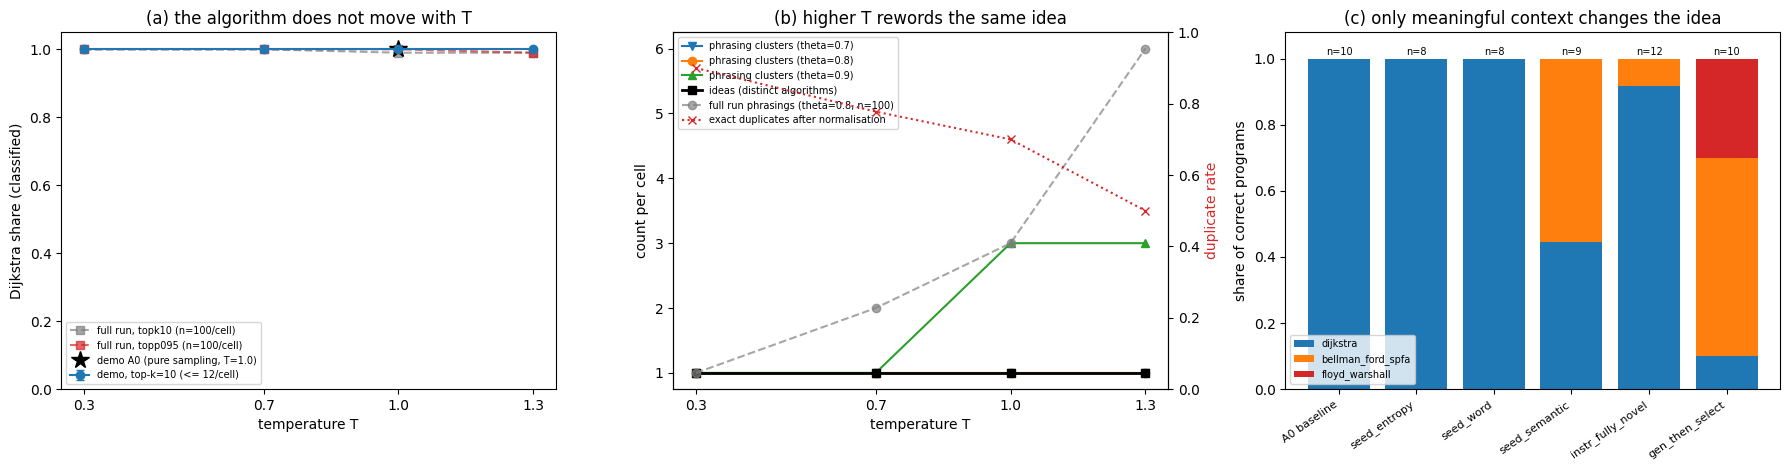

In [29]:
TEMPS_ = [0.3, 0.7, 1.0, 1.3]
COLM = {m: plt.get_cmap("tab10")(k) for k, m in enumerate(MODES[TASK] + ["other"])}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# (a) Dijkstra share vs temperature (demo cells with paraphrase-cluster bootstrap CI, full run dashed)
ax = axes[0]
ra = sorted([r for r in A["bfs_dijkstra_table"] if r["arm"] == "A1"], key=lambda r: r["T"])
y = np.array([r["share_classified"]["share"] for r in ra], dtype=float)
ci = np.array([[np.nan if v is None else v for v in r["share_classified"]["cluster_boot95"]] for r in ra], dtype=float)
ax.errorbar([r["T"] for r in ra], y, yerr=[np.nan_to_num(y - ci[:, 0]), np.nan_to_num(ci[:, 1] - y)], marker="o",
            capsize=3, color="#1f77b4", label=f"demo, top-k=10 (<= {MAX_PER_CELL}/cell)")
fr = sorted([r for r in ref["bfs_dijkstra_table"] if r["arm"] == "A1" and not r["thinking"]], key=lambda r: (r["sampler"], r["T"]))
for sampler, col in (("topk10", "#7f7f7f"), ("topp095", "#d62728")):
    xs = [r for r in fr if r["sampler"] == sampler]
    ax.plot([r["T"] for r in xs], [r["share_classified"] for r in xs], "s--", color=col, alpha=0.7,
            label=f"full run, {sampler} (n=100/cell)")
a0 = [r for r in A["bfs_dijkstra_table"] if r["arm"] == "A0"]
if a0:
    ax.plot([1.0], [a0[0]["share_classified"]["share"]], "k*", ms=13, label="demo A0 (pure sampling, T=1.0)")
ax.set_ylim(0, 1.05); ax.set_xticks(TEMPS_); ax.set_xlabel("temperature T"); ax.set_ylabel("Dijkstra share (classified)")
ax.set_title("(a) the algorithm does not move with T"); ax.legend(fontsize=7, loc="lower left")

# (b) ideas vs phrasings over T: distinct phrasings at three thresholds, ideas, and the exact-duplicate rate
ax = axes[1]
tb = sorted([r for r in A["ideas_by_phrasings"]["table"] if r["arm"] == "A1"], key=lambda r: r["T"])
for th, mk in ((0.7, "v"), (0.8, "o"), (0.9, "^")):
    ax.plot([r["T"] for r in tb], [r[f"theta{th}_single"]["n_phrasings"] for r in tb], marker=mk,
            label=f"phrasing clusters (theta={th})")
ax.plot([r["T"] for r in tb], [r["theta0.8_single"]["n_ideas"] for r in tb], "ks-", lw=2, label="ideas (distinct algorithms)")
fp = sorted([x for x in ref["ideas_by_phrasings"] if x["arm"] == "A1" and x["sampler"] == "topk10"], key=lambda x: x["T"])
ax.plot([x["T"] for x in fp], [x["n_phrasings"] for x in fp], "o--", color="grey", alpha=0.7,
        label="full run phrasings (theta=0.8, n=100)")
ax2 = ax.twinx()
ax2.plot([r["T"] for r in tb], [r["dup_rate_normalised"] for r in tb], "x:", color="#d62728",
         label="exact duplicates after normalisation")
ax2.set_ylim(0, 1); ax2.set_ylabel("duplicate rate", color="#d62728")
ax.set_xticks(TEMPS_); ax.set_xlabel("temperature T"); ax.set_ylabel("count per cell")
ax.set_title("(b) higher T rewords the same idea")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")

# (c) algorithm mix of correct programs per condition (analysis/figures.py fig6, plus gen-then-select)
ax = axes[2]
rs_ = A["seeds_instructions"]
names = ["A0 baseline"] + [r["condition"] for r in rs_] + ["gen_then_select"]
dists = ([rs_[0]["base_label_dist_correct"]] if rs_ else [A["gen_then_select"][TASK]["baseline_A0"]["idea_counts"]]) + \
        [r["label_dist_correct"] for r in rs_] + [A["gen_then_select"][TASK]["gen_then_select"]["idea_counts"]]
bottom = np.zeros(len(names))
for m in MODES[TASK] + ["other"]:
    v = np.array([d.get(m, 0) / max(sum(d.values()), 1) for d in dists])
    if v.sum() > 0:
        ax.bar(range(len(names)), v, bottom=bottom, color=COLM[m], label=m)
    bottom += v
for k, d in enumerate(dists):
    ax.text(k, 1.01, f"n={sum(d.values())}", ha="center", fontsize=7)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=35, ha="right", fontsize=8)
ax.set_ylim(0, 1.08); ax.set_ylabel("share of correct programs"); ax.legend(fontsize=7, loc="lower left")
ax.set_title("(c) only meaningful context changes the idea")
plt.tight_layout(); plt.show()

### Activation space: where do cues move the read-position state?

All three panels use Qwen3-8B's real layer-22 residual-stream states (4096-d) at the read position.

- **(d)** Paired displacement in the mode subspace, as a ratio to paraphrase noise. The red line is the 1.5×
  equivalence bound.
- **(e)** `analysis/figures.py` fig5: metric MDS of the centroid geometry of the forced-mode prompts (circles,
  coloured and sized by how often the model *naturally* implements each mode in the demo samples) and the condition
  prompts (red ×).
- **(f)** Every individual prompt state projected onto the first two axes of the mode subspace S_R, with arrows
  from the baseline centroid to each cue's centroid.

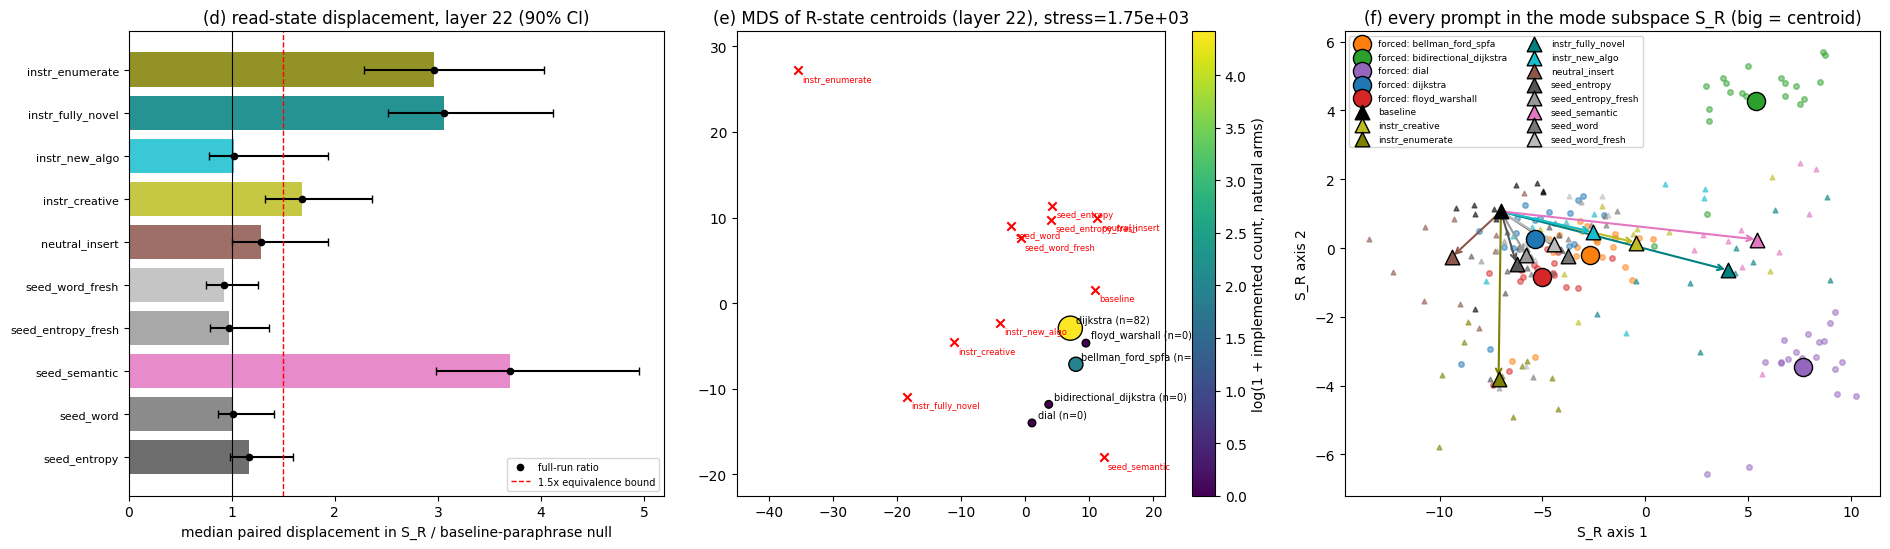

In [30]:
from sklearn.manifold import MDS

st = A["subspace_test"][TASK]["l_star"]
l = meta["l_star"][TASK]
Hn = load_state(f"R_named_{TASK}", l).astype(np.float64)
Hc = load_state(f"R_conditions_{TASK}", l).astype(np.float64)
yn = np.array([r["condition"].split(":")[1] for r in meta[f"R_named_{TASK}"]])
crow = meta[f"R_conditions_{TASK}"]
cond_of = np.array([r["condition"] for r in crow])
# condition colours (kept apart from the mode colours): random seeds/neutral in greys, semantic seed in pink,
# instructions in olive/cyan/teal
CCOL = {"baseline": "k", "seed_entropy": "#555555", "seed_word": "#777777", "seed_entropy_fresh": "#999999",
        "seed_word_fresh": "#bbbbbb", "neutral_insert": "#8c564b", "seed_semantic": "#e377c2",
        "instr_creative": "#bcbd22", "instr_new_algo": "#17becf", "instr_fully_novel": "#008080",
        "instr_enumerate": "#7f7f00"}
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))

# (d) displacement ratios (analysis/figures.py fig3, one task) with the full-run ratio as a black dot
ax = axes[0]
c = st["conditions"]
nm = list(c)
yv = [c[n]["ratio"] for n in nm]
lo = [c[n]["ratio"] - c[n]["ratio_ci90"][0] for n in nm]
hi = [c[n]["ratio_ci90"][1] - c[n]["ratio"] for n in nm]
ax.barh(range(len(nm)), yv, xerr=[lo, hi], color=[CCOL[n] for n in nm], capsize=3, alpha=0.85)
ax.plot([ref["subspace_test_l_star"]["conditions"][n]["ratio"] for n in nm], range(len(nm)), "k.", ms=9,
        label="full-run ratio")
ax.axvline(1.0, color="k", lw=0.8); ax.axvline(1.5, color="r", lw=1, ls="--", label="1.5x equivalence bound")
ax.set_yticks(range(len(nm))); ax.set_yticklabels(nm, fontsize=8)
ax.set_xlabel("median paired displacement in S_R / baseline-paraphrase null")
ax.set_title(f"(d) read-state displacement, layer {st['layer']} (90% CI)"); ax.legend(fontsize=7, loc="lower right")

# (e) analysis/figures.py fig5_mds (one task): MDS of forced-mode centroids and condition centroids
ax = axes[1]
modes = sorted(set(yn.tolist()))
conds = sorted({r["condition"] for r in crow})
pts = [Hn[yn == m].mean(0) for m in modes] + [Hc[[i for i, r in enumerate(crow) if r["condition"] == cc]].mean(0)
                                              for cc in conds]
P = np.array(pts)
D = np.linalg.norm(P[:, None] - P[None], axis=2)
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, normalized_stress="auto")
Y = mds.fit_transform(D)
nat = Counter(s["label"] for s in samples if s["task"] == TASK and s["arm"] in ("A0", "A1", "A2", "A3")
              or (s["task"] == TASK and s["arm"].startswith("A6")))
sizes = [30 + 3 * np.sqrt(nat.get(m, 0)) * 10 for m in modes]
sc = ax.scatter(Y[:len(modes), 0], Y[:len(modes), 1], s=sizes, c=[np.log1p(nat.get(m, 0)) for m in modes],
                cmap="viridis", edgecolor="k", zorder=3)
for k, m in enumerate(modes):
    ax.annotate(f"{m} (n={nat.get(m, 0)})", Y[k], fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.scatter(Y[len(modes):, 0], Y[len(modes):, 1], marker="x", color="r", zorder=4)
for k, cc in enumerate(conds):
    ax.annotate(cc, Y[len(modes) + k], fontsize=6, color="r", xytext=(3, -8), textcoords="offset points")
ax.margins(x=0.2, y=0.1)  # room for the point labels
ax.set_title(f"(e) MDS of R-state centroids (layer {l}), stress={mds.stress_:.3g}")
plt.colorbar(sc, ax=ax, label="log(1 + implemented count, natural arms)")

# (f) every prompt's state in the plane of the top-2 mode-subspace axes (basis_from_groups on the forced prompts)
ax = axes[2]
B, bmodes, Cc = basis_from_groups(Hn, yn)
mu = Hn.mean(0)
Zn, Zc = (Hn - mu) @ B[:, :2], (Hc - mu) @ B[:, :2]
for m in bmodes:
    ax.scatter(*Zn[yn == m].T, s=16, alpha=0.5, color=COLM[m])
    ax.scatter(*Zn[yn == m].mean(0), s=170, marker="o", color=COLM[m], edgecolor="k", zorder=4, label=f"forced: {m}")
base_c = Zc[cond_of == "baseline"].mean(0)
for cc in conds:
    Zi = Zc[cond_of == cc]
    ax.scatter(*Zi.T, s=12, marker="^", color=CCOL[cc], alpha=0.55)
    cen = Zi.mean(0)
    ax.scatter(*cen, s=110, marker="^", color=CCOL[cc], edgecolor="k", zorder=5, label=cc)
    if cc != "baseline":
        ax.annotate("", xy=cen, xytext=base_c, arrowprops=dict(arrowstyle="->", color=CCOL[cc], lw=1.5))
ax.set_xlabel("S_R axis 1"); ax.set_ylabel("S_R axis 2")
ax.set_title("(f) every prompt in the mode subspace S_R (big = centroid)")
ax.legend(fontsize=6.5, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

### What the model "intends" at the read position, and the trajectory variance (stored, full run)

- **(g)** The stored output of the linear probe, trained on forced-mode prompts and applied at R (`hooks/states.py`).
  It shows the probe's predicted mode distribution, averaged over the 10 paraphrases of each condition.
- **(h, i)** Section 8e (`variance_split`) needs the first 64 generated-token states of the 400 temperature-grid
  samples (about 105 MB per layer), so it is **not** re-run. The full-run values are plotted from the data instead.

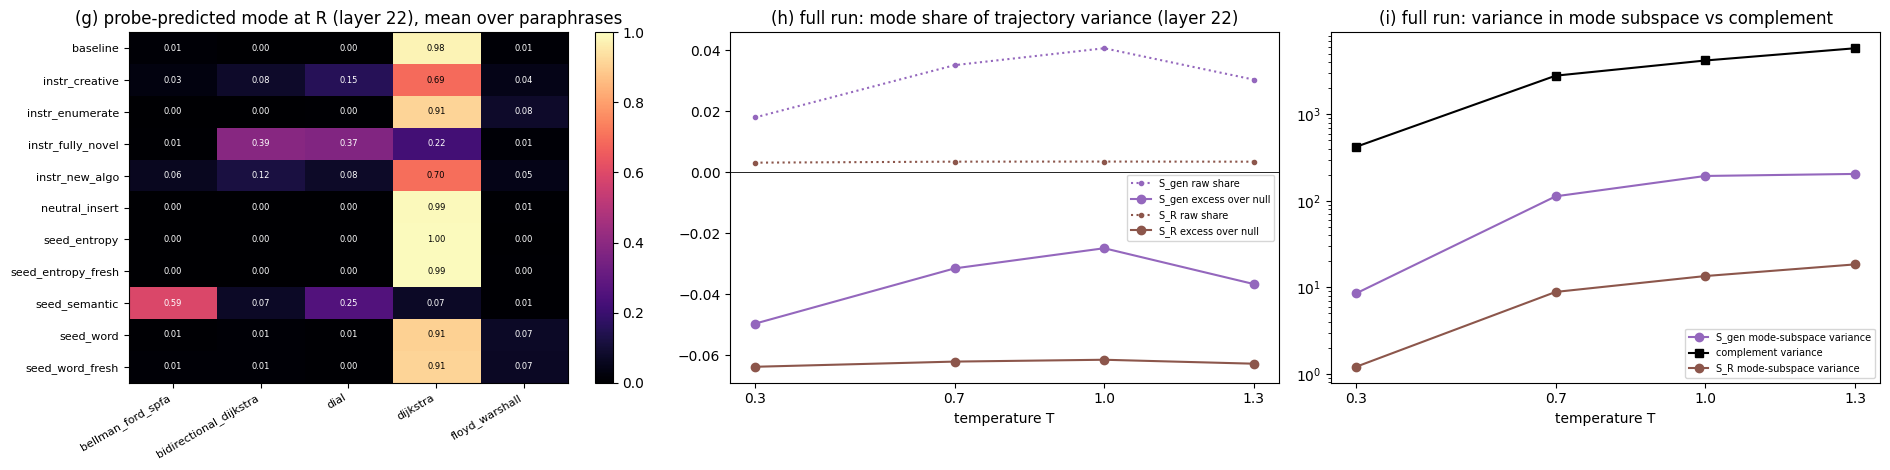

full-run variance-split slopes in T: {'S_gen': {'excess_share_dm': 0.015, 'excess_share_iso': 0.0141, 'mode_var': 206.1049, 'comp_var': 5352.2322, 'share': 0.0141}, 'S_R': {'excess_share_dm': 0.0012, 'excess_share_iso': 0.0003, 'mode_var': 17.1422, 'comp_var': 5541.1949, 'share': 0.0003}}


In [31]:
pr = load_state(f"R_conditions_probe_{TASK}")
pcls = meta[f"probe_classes_{TASK}"]
conds = sorted(set(cond_of.tolist()), key=lambda cc: (cc != "baseline", cc))
M = np.array([pr[cond_of == cc].mean(0) for cc in conds])
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
ax = axes[0]
im = ax.imshow(M, cmap="magma", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(pcls))); ax.set_xticklabels(pcls, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(conds))); ax.set_yticklabels(conds, fontsize=8)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w" if M[i, j] < 0.6 else "k")
plt.colorbar(im, ax=ax); ax.set_title(f"(g) probe-predicted mode at R (layer {l}), mean over paraphrases")

vs = ref["variance_split"]
for name, col in (("S_gen", "#9467bd"), ("S_R", "#8c564b")):
    per = vs["per_T"].get(name)
    if not per:
        continue
    x = [float(t) for t in per]
    axes[1].plot(x, [per[t]["share"] for t in per], marker=".", ls=":", color=col, label=f"{name} raw share")
    axes[1].plot(x, [per[t]["excess_share_dm"] for t in per], marker="o", color=col, label=f"{name} excess over null")
    axes[2].plot(x, [per[t]["mode_var"] for t in per], marker="o", color=col, label=f"{name} mode-subspace variance")
    if name == "S_gen":
        axes[2].plot(x, [per[t]["comp_var"] for t in per], marker="s", color="k", label="complement variance")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_title(f"(h) full run: mode share of trajectory variance (layer {vs['layer']})")
axes[2].set_yscale("log"); axes[2].set_title("(i) full run: variance in mode subspace vs complement")
for ax in axes[1:]:
    ax.set_xlabel("temperature T"); ax.set_xticks(TEMPS_); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("full-run variance-split slopes in T:", {n: {m: round(v["slope"], 4) for m, v in s.items()} for n, s in vs["slopes"].items()})

## Takeaways

- **Temperature is a phrasing knob, not an idea knob.** Dijkstra is 100% of the programs in every demo temperature
  cell, and at least 99% of classified programs in every full-run cell. Higher T removes exact duplicates and splits the same algorithm
  into more surface variants: the duplicate rate falls and the clusters at θ=0.9 multiply.
- **Random context seeds do nothing**, behaviourally or internally. Both random seeds and the neutral insert stay
  near paraphrase noise in the mode subspace: on T2 the entropy seed is 1.16× and the word seed 1.01×, though the
  entropy seed's 90% CI just reaches past the 1.5× bound.
- **Meaning moves the model.** The semantic seed is a story implying relaxation rounds. It shifts the read-position
  state 3.7× beyond paraphrase noise, and about half or more of its correct programs become Bellman-Ford. The shift
  points *away from Dijkstra* (cosine −0.63 with the Dijkstra centroid) rather than *at* the forced Bellman-Ford
  centroid (cosine −0.09). This direction is one of the reasons the pre-registered forecast P5 missed. The linear
  probe at R nonetheless puts 0.59 of its mass on Bellman-Ford for this condition (panel g).
- **Instructions and gen-then-select buy diversity at a price.** "Fully novel" moves the state about 3× but shifts
  behaviour only modestly. Gen-then-select yields the most distinct algorithms, at a lower pass rate.
- **Scale back up:** set `MAX_PER_CELL = 12` (the whole demo file), `N_BOOT = 2000`, `N_PERM = 5000`,
  `N_BOOT_PHRASING = 1000`, `N_BOOT_SUBSPACE = 2000`, `N_PERM_SUBSPACE = 10000` and `N_NULL_SUBSPACE = 100`. The
  full 5,220-sample run (both tasks, thinking on/off) needs the GPU stages of `method.py`.